# Septoria severity and yield loss in winter wheat (West Lafayette, Indiana)

This notebook simulates leaf blotch (septoria) severity, and the yield loss
it causes, for 19 winter-wheat seasons at West Lafayette, Indiana (sown
1972–1990, harvested 1973–1991). The severity observations are those of
Shaner and Buechley (1995, *Plant Disease* 79:928–938) for the susceptible
cultivar Monon at the Purdue Agronomy Farm. It has two stages.

1. **Crop growth** with torchcrop's **Lintul5** model in water- and
   nitrogen-limited production mode (rainfed, with the trial's nitrogen
   fertiliser):
   1. calibrate phenology (TSUM1, TSUM2) against reference anthesis and
      maturity dates;
   2. calibrate the level of simulated yield (the fertiliser-N recovery
      fraction) against detrended USDA NASS county yields.
2. **Disease** with simpest's **FraNchEstYN** model, driven by the calibrated
   crop growth and by hourly weather:
   1. screen the disease parameters for sensitivity (Morris);
   2. calibrate five disease parameters against the observed severity of the
      upper four leaves, simulated with simpest's upper-leaf tissue pool,
      with the rest fixed at their canonical FraNchEstYN values;
   3. simulate severity and yield loss, then check the fit and a hold-out.

Each "location" in the torchcrop dataset is one **sowing season** at the same
site, with its own sowing day (`IDPL` in `site.csv`). Each season's weather
starts on 1 January of the sowing year and runs 570 days, so the model is
driven with `start_doy=1` and relies on its internal **sowing latch** for the
pre-sowing spin-up.

## What the results can and cannot support

Read the results with these limits in mind. Each is explained where it
arises, and section 11 gives the numbers.

- **The yield level is a county yield, not the trial's attainable yield.**
  The crop model is calibrated to county-average farm yields, which already
  include disease and other losses and come from other cultivars and
  management than the Monon trial plots (section 3). The yield FraNchEstYN
  treats as attainable is therefore too low, and simulated loss is relative
  to it.
- **The yield loss is not checked against any measurement.** The damage
  coefficients keep their canonical FraNchEstYN values (section 8). They fix
  the level of the simulated losses; the differences between seasons come
  from simulated severity alone.
- **Severity is predicted loosely.** The model reproduces the average
  epidemic and part of the ranking of seasons, but its error on seasons left
  out of the calibration is about 19 severity points (section 10).
- **The observations are for the upper four leaves.** The paper's severity is
  the mean diseased area of the flag leaf and the three leaves below it, not
  of the whole canopy. The model is compared with them through an upper-leaf
  tissue pool, a simpest option that is not part of FraNchEstYN (section 5).
  From 1986 the dominant pathogen is *Stagonospora nodorum*, not *Septoria
  tritici*.
- **Every parameter value has a stated source:** a canonical FraNchEstYN or
  WOFOST value, a calibration in this notebook, or a figure from the paper.

## Torchcrop

### 1. Setup


In [1]:
import copy
import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import Dataset

from torchcrop import (CropParameters, SoilParameters, SiteParameters, Lintul5Model, WeatherDriver,)

plt.rcParams["font.family"] = "DeJavu Serif"
plt.rcParams["font.serif"] = "Times New Roman"

DATA_DIR = Path("west_lafayette_indiana_72_90")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [2]:
class TorchCropDataset(Dataset):
    """Reads per-location weather, soil, and site data for torchcrop.

    Directory layout (under ``DATA_DIR``)::

        weather/<location>.csv   daily forcing, one file per location
        soil/soil.csv            one row per location, indexed by ``location``
        site/site.csv            one row per location, indexed by ``location``

    Here each "location" is actually one **sowing season** (keyed by sowing
    year) at the same West Lafayette site, since Indiana's winter-wheat
    sowing date shifts year to year -- unlike the Brandenburg reference set,
    where each location is a distinct place sown on the same calendar date.
    Each season's weather file spans a fixed-length window starting 1
    January of the sowing year and running long enough into the following
    year to reach maturity, and each site.csv row carries that season's own
    ``IDPL``.

    ``__getitem__`` returns a single sample as a dict with:

        * ``weather`` : ``[T, 8]`` float tensor in torchcrop channel order
          (DOY, davtmp, tmin, tmax, irrad, rain, vp, wind)
        * ``soil``    : dict of scalar floats keyed by ``SoilParameters`` field
        * ``site``    : dict of scalar floats keyed by ``SiteParameters`` field

    Use `collate_torchcrop` as the DataLoader ``collate_fn`` to assemble a
    batch into ready-to-run ``WeatherDriver`` / ``SoilParameters`` /
    ``SiteParameters`` objects.
    """

    # CSV weather columns, in the exact order torchcrop expects them.
    WEATHER_COLS = [
        "Date",          # -> doy
        "TempMean",      # -> davtmp (recomputed as (TempMin+TempMax)/2 below)
        "TempMin",       # -> tmin
        "TempMax",       # -> tmax
        "Radiation",     # -> irrad
        "Precipitation", # -> rain
        "VapPressure",   # -> vp
        "Windspeed",     # -> wind
    ]

    # soil.csv column -> SoilParameters field name
    SOIL_MAP = {
        "SMDRY": "wcad",       # air-dry volumetric water content [m³ m⁻³]
        "SMW": "wcwp",         # water content at wilting point [m³ m⁻³]
        "SMFC": "wcfc",        # water content at field capacity [m³ m⁻³]
        "SMO": "wcst",         # water content at saturation [m³ m⁻³]
        "CRAIRC": "crairc",    # critical air content for aeration [m³ m⁻³]
        "SMI": "wci",          # initial root-zone moisture content [m³ m⁻³]
        "SMLOWI": "wci_lower", # initial lower-zone (sub-soil) moisture [m³ m⁻³]
        "RDMSO": "rdmso",      # max rooting depth allowed by the soil [m]
        "RUNFR": "runfr",      # fraction of rainfall lost to surface runoff [0–1]
        "CFEV": "cfev",        # soil-evaporation correction factor [-] (1–4)
        "KSUB": "ksub",        # max percolation rate to deeper layers [mm d⁻¹]
        "NMINS": "nmini",      # initial mineralisable soil organic N [g N m⁻²]
        "PMINS": "pmini",      # initial mineralisable soil organic P [g P m⁻²]
        "KMINS": "kmini",      # initial mineralisable soil organic K [g K m⁻²]
        "RTNMINS": "rtnmins",  # daily N mineralisation fraction [d⁻¹]
        "RTPMINS": "rtpmins",  # daily P mineralisation fraction [d⁻¹]
        "RTKMINS": "rtkmins",  # daily K mineralisation fraction [d⁻¹]
    }

    # site.csv column -> SiteParameters field name
    SITE_MAP = {
        "LATITUDE": "latitude",
        "ALTITUDE": "altitude",
        "IDPL": "idpl",
        "CO2": "co2",
    }

    def __init__(self, weather_dir, soil_dir, site_dir, dtype=torch.float32):
        super().__init__()
        self.weather_dir = Path(weather_dir)
        self.dtype = dtype
        self.soil_data = pd.read_csv(os.path.join(soil_dir, "soil.csv")).set_index("location")
        self.site_data = pd.read_csv(os.path.join(site_dir, "site.csv")).set_index("location")
        # Locations present in both soil and site tables.
        self.locations = self.soil_data.index.intersection(self.site_data.index)

    def __len__(self):
        return len(self.locations)

    def _load_weather(self, location):
        df = pd.read_csv(self.weather_dir / f"{location}.csv", parse_dates=["Date"], dayfirst=True)
        df = df[self.WEATHER_COLS].copy()
        # SIMPLACE drives phenology with TMPA = (TMIN+TMAX)/2 (Phenology.java:513),
        # not the measured TempMean; match it to reproduce the reference.
        df["TempMean"] = (df["TempMin"] + df["TempMax"]) / 2.0
        df["Radiation"] = df["Radiation"] / 1000.0   # kJ -> MJ m-2 d-1
        df["Date"] = df["Date"].dt.dayofyear          # date -> day-of-year
        return torch.as_tensor(df.values, dtype=self.dtype)  # [T, 8]

    def __getitem__(self, idx):
        location = self.locations[idx]

        weather = self._load_weather(location)

        srow = self.soil_data.loc[location]
        soil = {field: float(srow[col]) for col, field in self.SOIL_MAP.items()}

        trow = self.site_data.loc[location]
        site = {field: float(trow[col]) for col, field in self.SITE_MAP.items()}

        return {"weather": weather, "soil": soil, "site": site}


def collate_torchcrop(batch, dtype=torch.float32):
    """Collate samples into batched torchcrop driver/parameter objects.

    Args:
        batch: list of samples produced by `TorchCropDataset.__getitem__`.
        dtype: target dtype for the assembled tensors.

    Returns:
        Tuple ``(weather, soil_params, site_params)`` where ``weather`` is a
        `WeatherDriver` of shape ``[B, T, 8]`` and ``soil_params`` /
        ``site_params`` are batched dataclasses with ``[B]`` scalar fields.
    """
    # Weather: [B, T, 8]
    weather = torch.stack([s["weather"] for s in batch], dim=0).to(dtype)
    weather = WeatherDriver(weather)

    # Soil / site: stack each field across the batch into a [B] tensor.
    soil_fields = batch[0]["soil"].keys()
    soil_kwargs = {
        f: torch.tensor([s["soil"][f] for s in batch], dtype=dtype)
        for f in soil_fields
    }
    soil_params = SoilParameters(**soil_kwargs)

    site_fields = batch[0]["site"].keys()
    site_kwargs = {
        f: torch.tensor([s["site"][f] for s in batch], dtype=dtype)
        for f in site_fields
    }
    site_params = SiteParameters(**site_kwargs)

    return weather, soil_params, site_params

In [3]:
dataset = TorchCropDataset(
    weather_dir=DATA_DIR / "weather",
    soil_dir=DATA_DIR / "soil",
    site_dir=DATA_DIR / "site",
)

print(f"Dataset: {len(dataset)} locations")

Dataset: 19 locations


Water- and nitrogen-limited production is set with two switches. Both are
needed: with `iopt = 1` the model ignores water stress even when the soil
dries out.

| Switch             | Value | Effect                                                           |
| ------------------ | ----- | ---------------------------------------------------------------- |
| `crop_params.iopt` | `3`   | Run mode = water- and nitrogen-limited → water and N stress reduce growth; P and K stay non-limiting |
| `soil_params.irri` | `0`   | No irrigation → rainfall and the soil water balance set soil moisture |

**Soil.** The soil is the same for every season (`soil/soil.csv`). The
rooting depth the model can reach is the smaller of the soil limit (`RDMSO`,
2.0 m) and the crop limit (`rdmcr`, 1.25 m in the wheat preset), so 1.25 m
here. The soil supplies 30 kg N ha⁻¹ per season by mineralisation (`NMINS`).

**Nitrogen fertiliser.** Shaner and Buechley (1995) describe the trial's
fertilisation: in the earlier years about 22 kg N ha⁻¹ before planting plus
about 90 kg N ha⁻¹ as a spring topdressing, and in later years about
130 kg N ha⁻¹, all in autumn. The paper does not say when the practice
changed or give a topdressing date. The split is used here for every season,
with the topdressing assumed on 1 April. The share of applied N recovered by
the crop (`nrf`) starts at the preset 0.7 and is calibrated in section 3.

In [4]:
# Assemble every season into one batch; the model runs all of them in one forward pass.
samples = [dataset[i] for i in range(len(dataset))]
weather, soil_params, site_params = collate_torchcrop(samples)

# No irrigation (IRRI=0): rainfall and the soil water balance set soil moisture.
soil_params.irri = torch.tensor(0.0)

soil_params = soil_params.to(device=device)
site_params = site_params.to(device=device)
weather = weather.to(device=device)

# Winter-wheat preset in water- and nitrogen-limited mode (IOPT=3): water
# stress (TRANRF < 1 when the root zone dries) and nitrogen stress (NNI < 1)
# reduce growth; P and K stress are switched off.
crop_params = CropParameters(crop_name="wheat")
crop_params.iopt = torch.tensor(3.0)
crop_params = crop_params.to(device=device)

sow_years = np.array([int(y) for y in dataset.locations])
G_M2_TO_KG_HA = 10.0   # torchcrop biomass is g m-2; agronomic yields are kg ha-1

# Nitrogen fertiliser as daily applications aligned with the weather days:
# [season, day, (N, P, K)] in g m-2 d-1. Amounts from Shaner and Buechley
# (1995); the topdressing date is an assumption (see the text above).
N_AT_SOWING_KG_HA = 22.0
N_SPRING_KG_HA = 90.0
N_SPRING_DATE = "04-01"   # month-day in the harvest year
KG_HA_TO_G_M2 = 0.1

sowing_doy = dataset.site_data.loc[dataset.locations, "IDPL"].to_numpy().astype(int)
fertilizer = torch.zeros(len(sow_years), weather.data.shape[1], 3, device=device)
for b, sow_year in enumerate(sow_years):
    # Day index 0 is 1 January of the sowing year.
    spring_day = (pd.Timestamp(f"{sow_year + 1}-{N_SPRING_DATE}") - pd.Timestamp(f"{sow_year}-01-01")).days
    fertilizer[b, sowing_doy[b] - 1, 0] = N_AT_SOWING_KG_HA * KG_HA_TO_G_M2
    fertilizer[b, spring_day, 0] = N_SPRING_KG_HA * KG_HA_TO_G_M2


### 2. Calibrate phenology

Lintul5's development stage (DVS) runs from 0 at emergence to 1 at anthesis
and to 2 at maturity. After anthesis it advances with thermal time alone and
reaches 2 after `TSUM2` °C d. Before anthesis, each day's thermal time is
first multiplied by a day-length factor and a vernalisation factor
(`idsl = 2`), and anthesis is reached after `TSUM1` °C d of this *effective*
thermal time. Short days and an unmet cold requirement therefore hold the
crop back in autumn and winter, as in a real winter wheat.

The torchcrop wheat preset is temperature-only (`idsl = 0`) and has no values
for either factor. They are taken from the generic winter-wheat set of the
WOFOST crop parameter file (`wheat.yaml`,
[WOFOST_crop_parameters](https://github.com/ajwdewit/WOFOST_crop_parameters))
and kept fixed:

| Parameter (WOFOST name)                    | Value                                      | Meaning                                              |
| ------------------------------------------ | ------------------------------------------ | ---------------------------------------------------- |
| `phottb` (`DLC`, `DLO`)                    | 8 h, 14 h                                  | day-length factor rises from 0 at 8 h to 1 at 14 h   |
| `vernrt` (`VERNRTB`)                       | 0 below −4 °C, 1 at 3–10 °C, 0 above 17 °C | vernal days gained per day, by mean temperature      |
| `vbase` (`VERNBASE`)                       | 14 d                                       | vernal days before development starts                |
| `versat` (`VERNSAT`)                       | 70 d                                       | vernal days at which the cold requirement is met     |
| `vernalisation_devstage` (`VERNDVS`)       | 0.3                                        | DVS at which vernalisation switches off (the preset) |

Only `TSUM1` and `TSUM2` are fitted. Neither factor depends on them, as long
as the cold requirement is met before vernalisation switches off (checked
after the fit). The fit is therefore direct: run the model once with both
sums set out of reach, read each season's effective thermal time on its
reference anthesis date, and its thermal time between the reference anthesis
and maturity dates, and take the means. The means are the least-squares
estimates in thermal-time units.

The reference dates in `phenology/phenology.csv` come from Table 1 of Shaner
and Buechley (1995, *Plant Disease* 79:928–938), which reports planting,
spike emergence (heading) and harvest of the susceptible check cultivar Monon
at the Purdue Agronomy Farm, the same trials as the septoria observations
used below. The model's sowing days (`IDPL` in `site.csv`) are these planting
dates. The paper reports no anthesis or physiological maturity, so they are
derived with thermal time (base 0 °C, from the same weather the model uses):

- anthesis: observed heading + 70 °C d (3–6 days in these seasons);
- maturity: anthesis + 750 °C d, a typical soft red winter wheat grain fill.
  Derived maturity falls before the observed harvest in every season.

`TSUM1` is therefore fitted to observations (heading, shifted by a few
days), while `TSUM2` mostly reflects the assumed 750 °C d. The paper has no
1982 crop year; that season keeps a modelled degree-day reconstruction, so it
is the one season not anchored to observations.

In [5]:
# Winter-wheat phenology: temperature, day length and vernalisation (IDSL = 2).
# Fixed values from the generic winter-wheat set of the WOFOST crop parameter
# file (wheat.yaml, github.com/ajwdewit/WOFOST_crop_parameters).
DLC, DLO = 8.0, 14.0             # critical and optimum day length [h]
VERNBASE, VERNSAT = 14.0, 70.0   # vernal days: development starts / requirement met [d]
VERNRTB = [(-8.0, 0.0), (-4.0, 0.0), (3.0, 1.0), (10.0, 1.0), (17.0, 0.0), (20.0, 0.0)]  # vernal days per day vs mean temperature [°C]

crop_params.idsl = torch.tensor(2.0, device=device)
crop_params.phottb = torch.tensor([(0.0, 0.0), (DLC, 0.0), (DLO, 1.0), (24.0, 1.0)], device=device)
crop_params.vernrt = torch.tensor(VERNRTB, device=device)
crop_params.vbase = torch.tensor(VERNBASE, device=device)
crop_params.versat = torch.tensor(VERNSAT, device=device)

In [6]:
# Reference phenology is keyed by harvest year; a season sown in year y is harvested in y + 1.
pheno_ref = pd.read_csv(DATA_DIR / "phenology" / "phenology.csv")
pheno_ref = pheno_ref.set_index(pheno_ref["harvest_year"] - 1).reindex(sow_years)
PHENO_EVENTS = {"anthesis": "flowering_date", "maturity": "maturity_date"}

# Only seasons with reference dates enter the fit.
ref_rows = np.flatnonzero(pheno_ref["flowering_date"].notna().to_numpy())
print("seasons without reference phenology:", np.delete(sow_years, ref_rows).tolist())

# Weather starts on 1 January of each sowing year, so a date's index in the
# simulation is its day count from that 1 January.
season_start = pd.to_datetime([f"{y}-01-01" for y in sow_years])[ref_rows]
obs_idx = {ev: np.asarray((pd.to_datetime(pheno_ref[col].to_numpy()[ref_rows]) - season_start).days)
           for ev, col in PHENO_EVENTS.items()}

# The model sows on site.csv's IDPL; the reference used its own sowing dates.
idpl = dataset.site_data.loc[dataset.locations, "IDPL"].to_numpy()
sow_diff = pheno_ref["sowing_doy"].to_numpy()[ref_rows] - idpl[ref_rows]
print("reference sowing DOY minus model IDPL [d]:", dict(zip(sow_years[ref_rows].tolist(), sow_diff.astype(int).tolist())))

seasons without reference phenology: []
reference sowing DOY minus model IDPL [d]: {1972: 0, 1973: 0, 1974: 0, 1975: 0, 1976: 0, 1977: 0, 1978: 0, 1979: 0, 1980: 0, 1981: 9, 1982: 0, 1983: 0, 1984: 0, 1985: 0, 1986: 0, 1987: 0, 1988: 0, 1989: 0, 1990: 0}


In [7]:
# Probe run: TSUM1 and TSUM2 are set out of reach, so no season reaches
# anthesis, and DVS x TSUM1 is the effective thermal time since emergence
# (thermal time x day-length factor x vernalisation factor).
TSUM_PROBE = 1e4
probe_params = copy.deepcopy(crop_params)
probe_params.tsum1 = torch.tensor(TSUM_PROBE, device=device)
probe_params.tsum2 = torch.tensor(1e5, device=device)
with torch.no_grad():
    probe = Lintul5Model(probe_params, soil_params, site_params).eval().to(device)(weather, start_doy=1, fertilizer=fertilizer)

# Column d + 1 holds the value at the end of simulation day d.
tt_eff = probe.dvs.cpu().numpy() * TSUM_PROBE                            # effective thermal time
tsum = torch.stack([s.tsum for s in probe.states], dim=1).cpu().numpy()  # thermal time
tt_anthesis = tt_eff[ref_rows, obs_idx["anthesis"] + 1]
tt_grain_fill = tsum[ref_rows, obs_idx["maturity"] + 1] - tsum[ref_rows, obs_idx["anthesis"] + 1]

TSUM1 = float(tt_anthesis.mean())
TSUM2 = float(tt_grain_fill.mean())
print(f"TSUM1 = {TSUM1:.0f} °C d (preset {float(crop_params.tsum1):.0f}), "
      f"TSUM2 = {TSUM2:.0f} °C d (preset {float(crop_params.tsum2):.0f})")

crop_params.tsum1 = torch.tensor(TSUM1, device=device)
crop_params.tsum2 = torch.tensor(TSUM2, device=device)

TSUM1 = 869 °C d (preset 1050), TSUM2 = 760 °C d (preset 1000)


anthesis : RMSE 3.2 d, bias +0.6 d, max |error| 6 d
maturity : RMSE 2.6 d, bias +0.4 d, max |error| 5 d


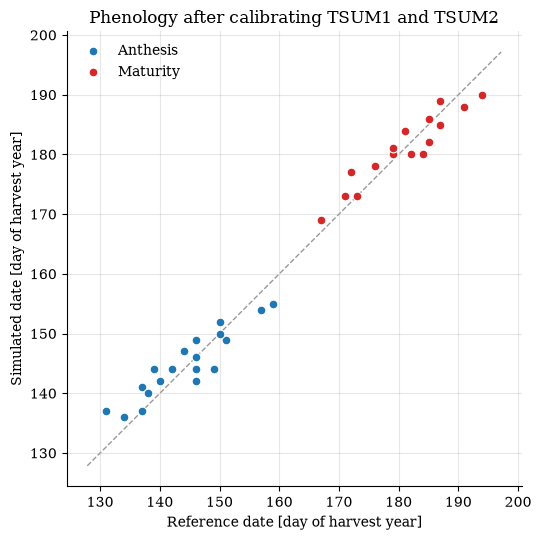

In [8]:
# Water- and nitrogen-limited run with the fitted TSUMs.
model = Lintul5Model(crop_params, soil_params, site_params).eval().to(device)
with torch.no_grad():
    output = model(weather, start_doy=1, fertilizer=fertilizer)

dvs_end = output.dvs.cpu().numpy()[:, 1:]   # DVS at the end of each simulation day
assert (dvs_end >= 2.0).any(axis=1).all(), "a season does not reach maturity"

# The TSUM1 fit assumes the cold requirement is met before vernalisation switches off.
vern_end = torch.stack([s.vern for s in output.states], dim=1).cpu().numpy()[:, 1:]
vern_off = np.argmax(dvs_end >= float(crop_params.vernalisation_devstage), axis=1)
assert (vern_end[np.arange(len(vern_off)), vern_off] >= VERNSAT).all(), "vernalisation incomplete at switch-off"

sim_idx = {"anthesis": np.argmax(dvs_end >= 1.0, axis=1)[ref_rows],
           "maturity": np.argmax(dvs_end >= 2.0, axis=1)[ref_rows]}

pheno_fit = pd.DataFrame(index=pd.Index(sow_years[ref_rows], name="sow_year"))
for ev in PHENO_EVENTS:
    pheno_fit[f"{ev}_ref"] = (season_start + pd.to_timedelta(obs_idx[ev], unit="D")).date
    pheno_fit[f"{ev}_sim"] = (season_start + pd.to_timedelta(sim_idx[ev], unit="D")).date
    pheno_fit[f"{ev}_error_d"] = sim_idx[ev] - obs_idx[ev]
    err = pheno_fit[f"{ev}_error_d"]
    print(f"{ev:9s}: RMSE {np.sqrt((err ** 2).mean()):.1f} d, bias {err.mean():+.1f} d, max |error| {err.abs().max()} d")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
for ev, color in (("anthesis", "#1f77b4"), ("maturity", "#d62728")):
    doy_ref = pd.to_datetime(pheno_fit[f"{ev}_ref"]).dt.dayofyear
    doy_sim = pd.to_datetime(pheno_fit[f"{ev}_sim"]).dt.dayofyear
    ax.scatter(doy_ref, doy_sim, s=40, color=color, edgecolor="white", linewidth=0.8, label=ev.capitalize(), zorder=3)
lo, hi = ax.get_xlim()
ax.plot([lo, hi], [lo, hi], color="0.6", lw=1, ls="--", zorder=1)
ax.set_xlabel("Reference date [day of harvest year]")
ax.set_ylabel("Simulated date [day of harvest year]")
ax.set_title("Phenology after calibrating TSUM1 and TSUM2")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend(frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

# pheno_fit

### 3. Calibrate yield

#### Observed yield (Tippecanoe County)

County-average winter wheat yields from USDA NASS for Tippecanoe County (which
contains West Lafayette), reported in bu/acre by **harvest year**. Yields rise
over the years as varieties, fertiliser and disease control improve, which a
model run with one fixed variety cannot reproduce. A straight-line trend is
fitted to the record (harvest years 1972–1991) and used below to detrend it.

Trend +66.4 kg ha-1 yr-1, RMSE around it 550 kg ha-1


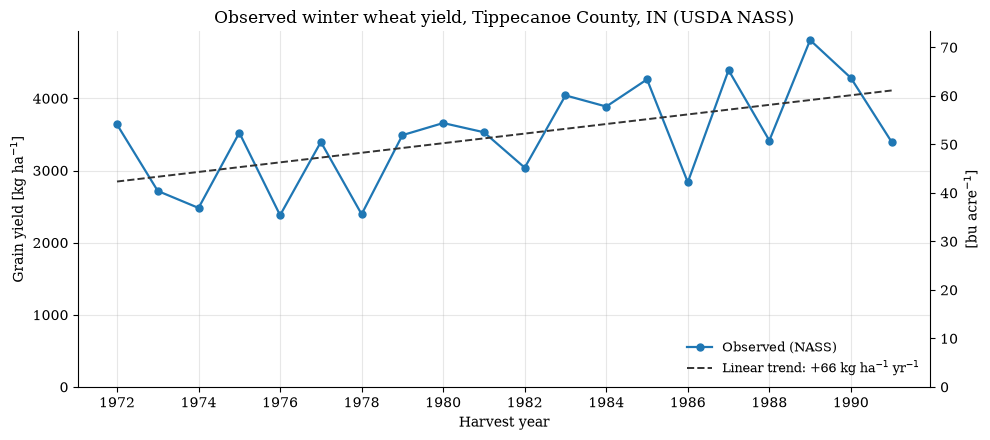

In [9]:
from simpest.models import observed_yield

# NASS "Year" is the harvest year; read_nass_yield also converts bu/acre to
# kg/ha (winter wheat is 60 lb per bushel, so 1 bu/acre ≈ 67.25 kg/ha).
obs_yield = observed_yield.read_nass_yield(DATA_DIR / "yield" / "yield.csv")
BU_ACRE_TO_KG_HA = observed_yield.BU_ACRE_TO_KG_HA

yield_trend = observed_yield.fit_linear_trend(obs_yield["harvest_year"], obs_yield["yield_kg_ha"])
print(f"Trend {yield_trend.slope:+.1f} kg ha-1 yr-1, RMSE around it {yield_trend.rmse:.0f} kg ha-1")

years = obs_yield["harvest_year"].to_numpy()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(years, obs_yield["yield_kg_ha"], color="#1f77b4", lw=1.6, marker="o", ms=5, zorder=3, label="Observed (NASS)")
ax.plot(years, yield_trend(years), color="0.2", lw=1.4, ls="--", zorder=4,
        label=f"Linear trend: {yield_trend.slope:+.0f} kg ha$^{{-1}}$ yr$^{{-1}}$")
ax.set_xlabel("Harvest year")
ax.set_ylabel("Grain yield [kg ha$^{-1}$]")
ax.set_title("Observed winter wheat yield, Tippecanoe County, IN (USDA NASS)")
ax.set_xticks(years[::2])
ax.set_ylim(0, None)
ax.grid(alpha=0.3)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
# Same quantity in the source unit, so a secondary scale is safe here.
sec = ax.secondary_yaxis("right", functions=(lambda v: v / BU_ACRE_TO_KG_HA, lambda v: v * BU_ACRE_TO_KG_HA))
sec.set_ylabel("[bu acre$^{-1}$]")
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

#### Water- and nitrogen-limited vs observed yield

The model uses one fixed variety and management for every season, so it has
no technology trend. To compare like with like, each observed yield is
**detrended** with the trend above and expressed at the technology level of
the middle simulated harvest year (1982). With a straight-line trend this
leaves the mean observed yield of the simulated seasons unchanged: early
years move up, late years move down. The observed yields are also converted to dry
matter (NASS reports grain at 13.5 % moisture), and each season is matched to
its NASS harvest year (sowing year + 1).

The left panel compares the levels (the gap between the curves is the yield
gap). The potential yield, from the same model with water and nitrogen
stress switched off, is shown for reference: the distance between the two
simulated curves is the yield lost to water and nitrogen shortage. The right
panel compares year-to-year anomalies: if the simulated yield explained the
good and bad years, the points would follow the diagonal.


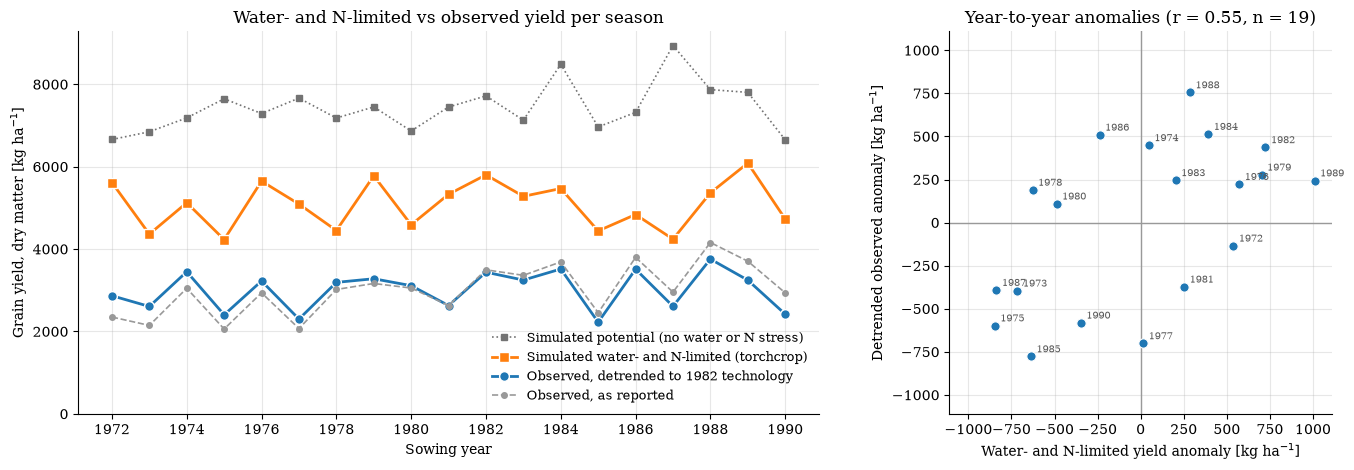

Mean observed/limited ratio (detrended): 0.59
Mean limited/potential ratio: 0.69
Anomaly correlation with detrended observed yield: limited r = 0.55, potential r = 0.19


In [10]:
# Compare the observed yields of the simulated seasons with torchcrop's
# water- and nitrogen-limited yield. Two adjustments make them comparable:
#   1. Year alignment: a season sown in year y is harvested (and reported by
#      NASS) in y + 1.
#   2. Technology: the model uses one fixed variety and management, so the
#      observed yields are detrended with the linear trend and expressed at
#      the technology level of the middle simulated harvest year, which keeps
#      their mean over the simulated seasons unchanged.
# NASS yields are at 13.5 % grain moisture; Lintul5's WSO is dry matter.
ref_harvest_year = int(round((sow_years + 1).mean()))
cmp_df = observed_yield.compare_with_potential(
    obs_yield, sow_years, output.yield_.cpu().numpy() * G_M2_TO_KG_HA, yield_trend,
    ref_harvest_year=ref_harvest_year,
).rename(columns={"potential": "limited"})   # the helper names its simulated column "potential"

# Potential-production reference: the same model with water and nitrogen
# stress switched off (IOPT=1, automatic irrigation), to show what they cost.
pot_crop, pot_soil = copy.deepcopy(crop_params), copy.deepcopy(soil_params)
pot_crop.iopt = torch.tensor(1.0, device=device)
pot_soil.irri = torch.tensor(1.0, device=device)
with torch.no_grad():
    pot_output = Lintul5Model(pot_crop, pot_soil, site_params).eval().to(device)(weather, start_doy=1, fertilizer=fertilizer)
cmp_df["potential"] = pot_output.yield_.cpu().numpy() * G_M2_TO_KG_HA

# Year-to-year anomalies (deviation from each series' own mean): does the
# water- and nitrogen-limited yield explain the good and bad years?
valid = cmp_df.dropna(subset=["observed"])
anom_sim = valid["limited"] - valid["limited"].mean()
anom_obs = valid["observed_detrended"] - valid["observed_detrended"].mean()
r_anom = np.corrcoef(anom_sim, anom_obs)[0, 1]
r_anom_pot = np.corrcoef(valid["potential"], valid["observed_detrended"])[0, 1]

fig, (ax_ts, ax_sc) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})

ax_ts.plot(cmp_df["sow_year"], cmp_df["potential"], color="0.45", lw=1.2, ls=":", marker="s", ms=4,
           label="Simulated potential (no water or N stress)")
ax_ts.plot(cmp_df["sow_year"], cmp_df["limited"], color="#ff7f0e", lw=2, marker="s", ms=7,
           markeredgecolor="white", label="Simulated water- and N-limited (torchcrop)")
ax_ts.plot(cmp_df["sow_year"], cmp_df["observed_detrended"], color="#1f77b4", lw=2, marker="o", ms=7,
           markeredgecolor="white", label=f"Observed, detrended to {ref_harvest_year} technology")
ax_ts.plot(cmp_df["sow_year"], cmp_df["observed"], color="0.6", lw=1.2, ls="--", marker="o", ms=4,
           label="Observed, as reported")
ax_ts.set_xlabel("Sowing year")
ax_ts.set_ylabel("Grain yield, dry matter [kg ha$^{-1}$]")
ax_ts.set_title("Water- and N-limited vs observed yield per season")
ax_ts.set_xticks(cmp_df["sow_year"][::2])
ax_ts.set_ylim(0, None)
ax_ts.legend(loc="lower right", frameon=False, fontsize=9)

lim = 1.1 * max(anom_sim.abs().max(), anom_obs.abs().max())
ax_sc.axhline(0, color="0.6", lw=1)
ax_sc.axvline(0, color="0.6", lw=1)
ax_sc.scatter(anom_sim, anom_obs, s=45, color="#1f77b4", edgecolor="white", linewidth=0.8, zorder=3)
for sy, xa, ya in zip(valid["sow_year"], anom_sim, anom_obs):
    ax_sc.annotate(str(sy), (xa, ya), xytext=(4, 3), textcoords="offset points", fontsize=7, color="0.35")
ax_sc.set_xlim(-lim, lim)
ax_sc.set_ylim(-lim, lim)
ax_sc.set_aspect("equal")
ax_sc.set_xlabel("Water- and N-limited yield anomaly [kg ha$^{-1}$]")
ax_sc.set_ylabel("Detrended observed anomaly [kg ha$^{-1}$]")
ax_sc.set_title(f"Year-to-year anomalies (r = {r_anom:.2f}, n = {len(valid)})")

for ax in (ax_ts, ax_sc):
    ax.grid(alpha=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig.tight_layout()
plt.show()

print(f"Mean observed/limited ratio (detrended): {cmp_df['yield_gap_ratio'].mean():.2f}")
print(f"Mean limited/potential ratio: {(cmp_df['limited'] / cmp_df['potential']).mean():.2f}")
print(f"Anomaly correlation with detrended observed yield: limited r = {r_anom:.2f}, potential r = {r_anom_pot:.2f}")
# cmp_df.round(1)

#### Calibrate simulated yield (WSO) against detrended observed yield

torchcrop is differentiable, so its parameters can be fitted by gradient
descent. `torchcrop.calibration.CalibrationManager` keeps each parameter
inside its bounds through a sigmoid transform, and L-BFGS minimises the mean
squared error between the simulated storage-organ weight at maturity (WSO)
and the detrended observed yield of every season. Phenology stays at the
TSUMs fitted in section 2.

**Which parameter.** The crop is nitrogen-limited, so the yield level is set
by how much nitrogen the crop takes up. The fitted parameter is therefore the
fertiliser-N recovery fraction `nrf`, the share of applied N that reaches the
crop (preset 0.7). Simulated yield rises steadily with `nrf`. The RUE scale
factor is not used: under nitrogen limitation yield first rises and then
falls as RUE increases, so it cannot be fitted by gradient descent, and
lowering RUE until the level matches removes the nitrogen limitation and with
it most of the year-to-year signal.

**What the fit can and cannot do.** One parameter set is shared by all 19
seasons, so the fit moves the level of the simulated yields; the
season-to-season pattern comes from the weather. The fitted `nrf` is an
*effective* value: besides fertiliser losses it absorbs every yield-limiting
factor the model still leaves out (other nutrients, weeds, pests, and also
disease).

**The target is not the trial's attainable yield.** FraNchEstYN needs the
yield the crop would reach without disease. County yields are something else
in three ways:

- they are *actual* farm yields, so they already include disease losses, and
  part of the septoria loss simulated in section 8 is counted twice;
- they come from many cultivars, several of them resistant to *Septoria
  tritici* from the late 1970s on (Shaner and Buechley 1995, p. 936), not
  from the very susceptible Monon;
- they average farm management, not the management of the trial plots.

The paper reports no plot yields. It gives only the range of Indiana state
average yields for 1973–1991, 2,353 to 3,966 kg ha⁻¹ (p. 928), which is in
line with the county record used here. Plot yields for Monon and for the
best entries are published in the annual Purdue performance-trial bulletins
the paper cites ("Performance of public and private small grains in
Indiana", Purdue Univ. Agric. Exp. Stn. Bull.). The yield of the best entry
in each year's trial would be the right calibration target; until those
bulletins are transcribed, the calibrated yield should be read as a
county-level yield and the simulated loss as relative to it.

In [11]:
from torchcrop.calibration import CalibrationManager, ParameterSpec

# Parameter to fit: the fertiliser-N recovery fraction. The whole batch of
# seasons shares one value, so the fit moves the level of the simulated yield;
# the season-to-season pattern comes from the weather. Phenology (tsum1/tsum2)
# stays at the values fitted in section 2.
CALIB_SPECS = [
    ParameterSpec("crop.nrf", bounds=(0.1, 0.9)),
]
MAX_EVALS = 30   # each evaluation is one forward + backward pass over all seasons

# Target: detrended observed yield (dry matter) per season, in kg ha-1.
target_kg_ha = torch.tensor(cmp_df["observed_detrended"].to_numpy(), dtype=torch.float32, device=device)
has_obs = ~torch.isnan(target_kg_ha)

# Calibrate a copy so `model` and `output` above stay the uncalibrated water- and nitrogen-limited run.
# deepcopy carries the fitted TSUMs over.
calib_model = Lintul5Model(copy.deepcopy(crop_params), soil_params, site_params).to(device)
calib_mgr = CalibrationManager(calib_model, CALIB_SPECS)

# L-BFGS with a line search: few parameters and a smooth objective, so it
# converges in a handful of evaluations. The latents are unconstrained; the
# manager maps them into the bounds on every materialize().
optimizer = torch.optim.LBFGS(calib_mgr.parameters(), lr=1.0, max_iter=MAX_EVALS, max_eval=MAX_EVALS,
                              tolerance_change=1e-4, line_search_fn="strong_wolfe")
history = []

def closure():
    optimizer.zero_grad()
    values = calib_mgr.materialize()
    sim_kg_ha = calib_model(weather, start_doy=1, fertilizer=fertilizer).yield_ * G_M2_TO_KG_HA
    loss = torch.mean((sim_kg_ha[has_obs] - target_kg_ha[has_obs]) ** 2)
    loss.backward()
    history.append({"eval": len(history), "rmse_kg_ha": float(loss.detach().sqrt()),
                    **{k: float(v.detach()) for k, v in values.items()}})
    print(f"eval {history[-1]['eval']:2d}  RMSE {history[-1]['rmse_kg_ha']:7.1f} kg ha-1  "
          + "  ".join(f"{k}={v:.3f}" for k, v in history[-1].items() if k.startswith("crop.")))
    return loss

optimizer.step(closure)
history = pd.DataFrame(history)

# Final forward pass with the calibrated values.
with torch.no_grad():
    calib_values = {k: float(v) for k, v in calib_mgr.materialize().items()}
    calib_output = calib_model(weather, start_doy=1, fertilizer=fertilizer)
cmp_df["calibrated"] = calib_output.yield_.cpu().numpy() * G_M2_TO_KG_HA
print("Calibrated:", {k: round(v, 3) for k, v in calib_values.items()})

valid = cmp_df.dropna(subset=["observed_detrended"])
fit_table = pd.DataFrame({
    "limited": observed_yield.fit_stats(valid["limited"], valid["observed_detrended"]),
    "calibrated": observed_yield.fit_stats(valid["calibrated"], valid["observed_detrended"]),
}).T.round(2)
fit_table

eval  0  RMSE  2135.1 kg ha-1  crop.nrf=0.700
eval  1  RMSE  1111.7 kg ha-1  crop.nrf=0.520
eval  2  RMSE  1092.8 kg ha-1  crop.nrf=0.192
eval  3  RMSE   827.8 kg ha-1  crop.nrf=0.247
eval  4  RMSE   954.8 kg ha-1  crop.nrf=0.491
eval  5  RMSE   463.0 kg ha-1  crop.nrf=0.357
eval  6  RMSE   464.0 kg ha-1  crop.nrf=0.365
eval  7  RMSE   462.8 kg ha-1  crop.nrf=0.359
eval  8  RMSE   462.8 kg ha-1  crop.nrf=0.360
eval  9  RMSE   462.8 kg ha-1  crop.nrf=0.360
Calibrated: {'crop.nrf': 0.36}


,RMSE,bias,r
limited,2135.08,2075.81,0.55
calibrated,462.85,-12.00,0.51


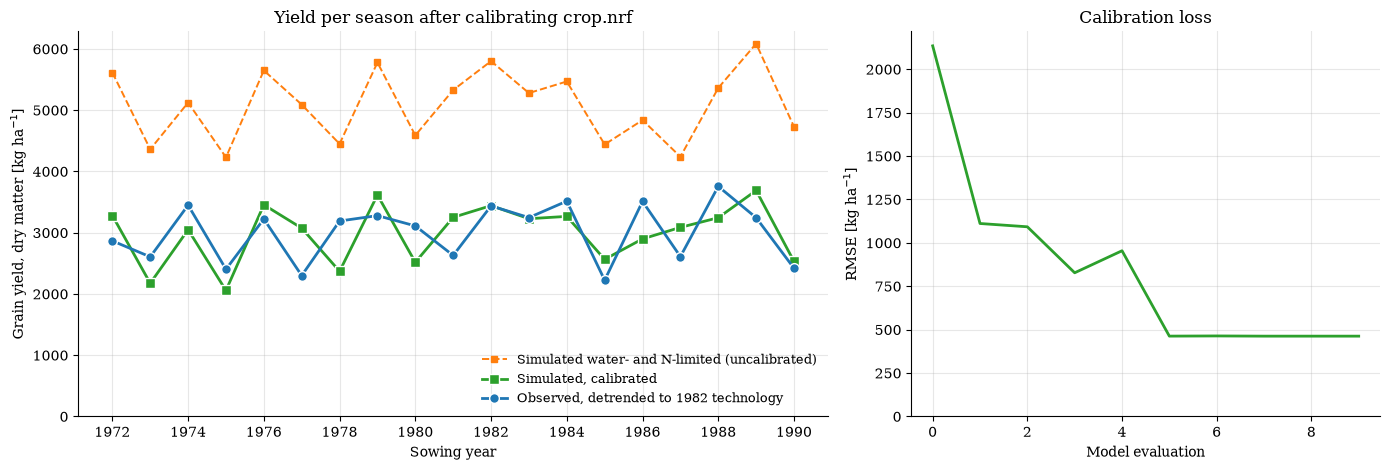

In [12]:
fig, (ax_ts, ax_loss) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})

ax_ts.plot(cmp_df["sow_year"], cmp_df["limited"], color="#ff7f0e", lw=1.4, ls="--", marker="s", ms=5,
           label="Simulated water- and N-limited (uncalibrated)")
ax_ts.plot(cmp_df["sow_year"], cmp_df["calibrated"], color="#2ca02c", lw=2, marker="s", ms=7,
           markeredgecolor="white", label="Simulated, calibrated")
ax_ts.plot(cmp_df["sow_year"], cmp_df["observed_detrended"], color="#1f77b4", lw=2, marker="o", ms=7,
           markeredgecolor="white", label=f"Observed, detrended to {ref_harvest_year} technology")
ax_ts.set_xlabel("Sowing year")
ax_ts.set_ylabel("Grain yield, dry matter [kg ha$^{-1}$]")
ax_ts.set_title("Yield per season after calibrating " + ", ".join(s.name for s in CALIB_SPECS))
ax_ts.set_xticks(cmp_df["sow_year"][::2])
ax_ts.set_ylim(0, None)
ax_ts.legend(loc="lower right", frameon=False, fontsize=9)

ax_loss.plot(history["eval"], history["rmse_kg_ha"], color="#2ca02c", lw=2)
ax_loss.set_xlabel("Model evaluation")
ax_loss.set_ylabel("RMSE [kg ha$^{-1}$]")
ax_loss.set_title("Calibration loss")
ax_loss.set_ylim(0, None)

for ax in (ax_ts, ax_loss):
    ax.grid(alpha=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig.tight_layout()
plt.show()

### 4. Crop growth of the calibrated run

The calibrated run (`crop_output`) drives FraNchEstYN in the rest of the
notebook. It returns two per-day trajectories that are plotted the same way:

- **State variables**: `crop_output.states`, a list of `ModelState` holding
  the model's stored pools (biomass, LAI, soil water, nutrient pools, …).
- **Diagnostic variables**: `crop_output.diagnostics`, a list of
  `DiagnosticState` holding the intermediate fluxes and stress factors
  computed each day (TRANRF, RUE, partitioning fractions, transpiration, …).

Masking to the sowing latch makes every curve **start at the day of
sowing**. The short near-vertical segment at DVS `0` is the sowing→emergence
interval; DVS then climbs `0 → 1` (anthesis) `→ 2` (maturity).


In [13]:
# The calibrated run is the crop growth used from here on.
crop_output = calib_output

from matplotlib.lines import Line2D

# Pick five random (reproducible) locations
rng = np.random.default_rng(42)
selected_idx = rng.choice(len(dataset.locations), size=5, replace=False)
locations = [dataset.locations[i] for i in selected_idx]
n_loc = len(locations)
colors = [
    "#1f77b4",  # blue
    "#d62728",  # red
    "#2ca02c",  # green
    "#ff7f0e",  # orange
    "#9467bd",  # purple
]

def mask_until_dvs2(sown_mask, dvs_vals):
    """Boolean mask selecting sown days up to and including maturity (DVS >= 2).

    Args:
        sown_mask: ``[L]`` bool array, ``True`` once the crop is sown.
        dvs_vals:  ``[L]`` development-stage values.

    Returns:
        ``[L]`` bool mask: sown days with index <= the first day DVS reaches 2.
    """
    mature = np.where(dvs_vals >= 2.0)[0]
    cutoff = mature[0] if len(mature) else len(dvs_vals)
    return sown_mask & (np.arange(len(dvs_vals)) <= cutoff)


def plot_trajectories(traj, dvs, sown, field_names, meta, *, title, ncols=4):
    """Plot every channel of ``traj`` against DVS, one line per location.

    A single helper used for both state and diagnostic figures so they share
    the same style, grid layout, labelling and legend.

    Args:
        traj:        ``[B, L, C]`` stacked trajectory array.
        dvs:         ``[B, L]`` development stage (x-axis).
        sown:        ``[B, L]`` sowing latch (> 0 once sown).
        field_names: length-``C`` list naming the channels of ``traj``.
        meta:        ``{field: (label, unit)}`` used for the panel titles.
        title:       figure super-title.
        ncols:       number of subplot columns.
    """
    nrows = int(np.ceil(len(field_names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 2.4 * nrows), sharex=True)
    axes = axes.ravel()

    for ax, fld in zip(axes, field_names):
        j = field_names.index(fld)
        for c, b in enumerate(selected_idx):
            mask = mask_until_dvs2(sown[b] > 0, dvs[b])
            ax.plot(dvs[b][mask], traj[b, mask, j], color=colors[c], lw=1.2, alpha=0.9)
        label, unit = meta.get(fld, (fld, ""))
        ax.set_title(f"{label} [{unit}]" if unit else label, fontsize=11)
        ax.grid(alpha=0.3)
        ax.margins(x=0.02)

    # Hide unused panels; label the x-axis on the bottom row of plotted panels.
    for ax in axes[len(field_names):]:
        ax.axis("off")
    for ax in axes[max(0, len(field_names) - ncols):len(field_names)]:
        ax.set_xlabel("DVS")

    handles = [Line2D([0], [0], color=colors[i], lw=2) for i in range(n_loc)]
    fig.legend(
        handles,
        [str(loc) for loc in locations],
        title="Location",
        loc="lower center",
        ncol=n_loc,
        fontsize=12,
        bbox_to_anchor=(0.5, 0.01),
        frameon=False,
    )
    fig.suptitle(title, fontsize=13)
    fig.tight_layout(rect=[0, 0.04, 1, 0.99])
    plt.show()

#### State variables vs DVS

Stack the per-day `ModelState` snapshots into a `[B, T+1, C]` array and plot
every stored state variable against DVS with the shared helper.


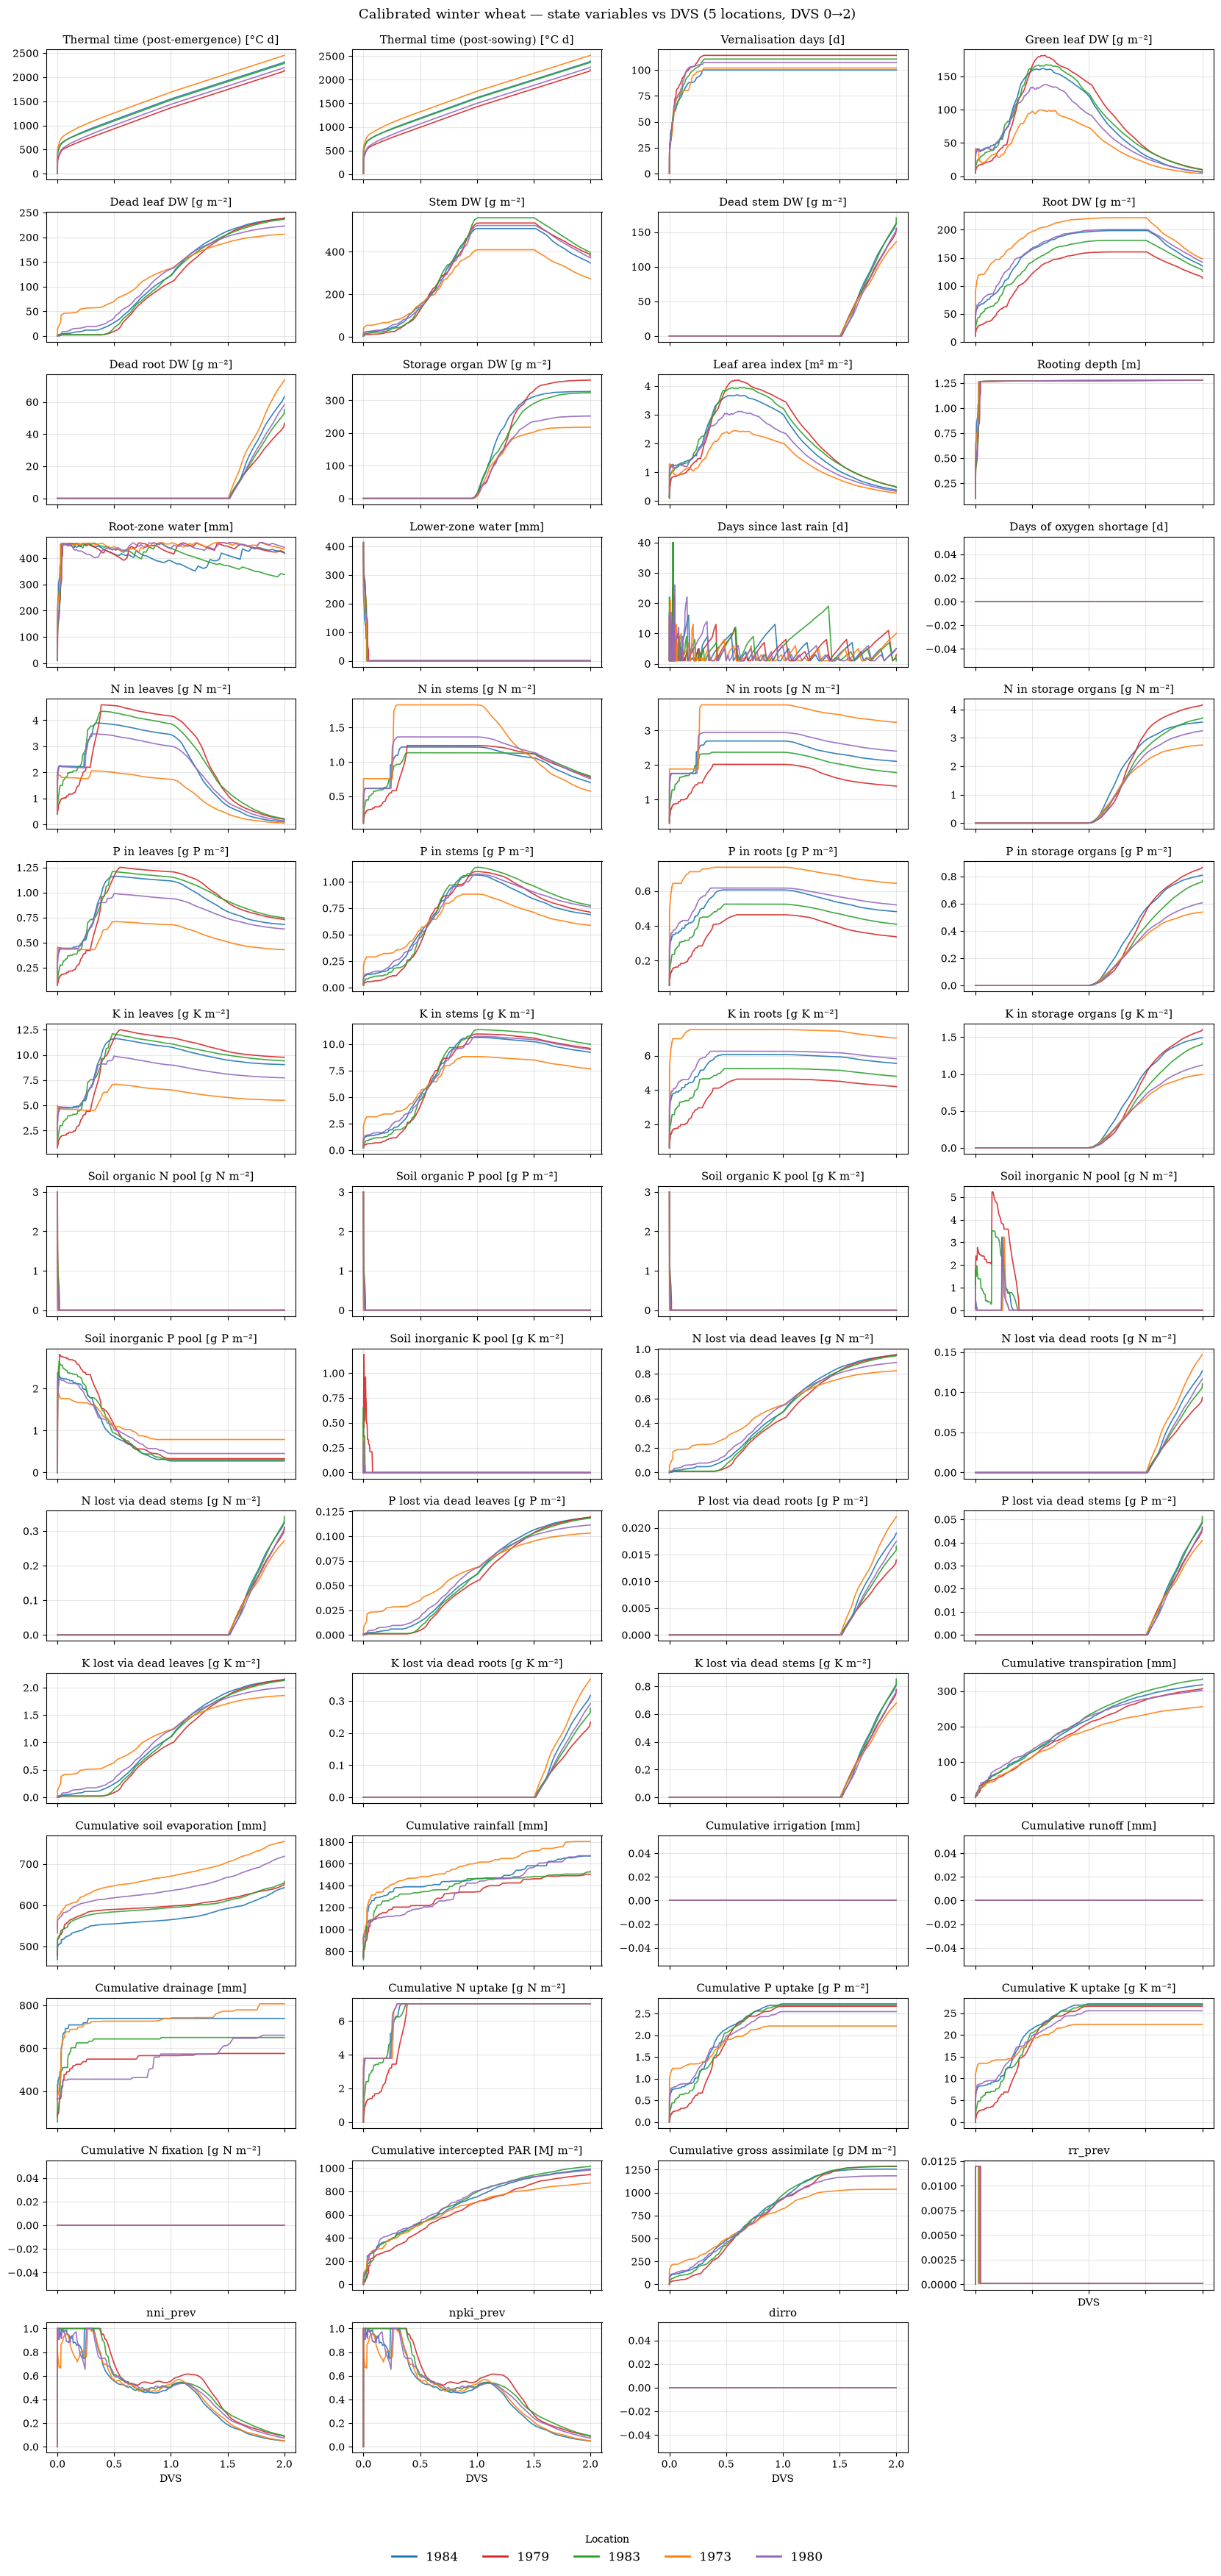

In [14]:
# Label + unit for each ModelState field.
STATE_META = {
    "tsum": ("Thermal time (post-emergence)", "°C d"),
    "tsump": ("Thermal time (post-sowing)", "°C d"),
    "vern": ("Vernalisation days", "d"),
    "wlv": ("Green leaf DW", "g m⁻²"),
    "wlvd": ("Dead leaf DW", "g m⁻²"),
    "wst": ("Stem DW", "g m⁻²"),
    "wstd": ("Dead stem DW", "g m⁻²"),
    "wrt": ("Root DW", "g m⁻²"),
    "wrtd": ("Dead root DW", "g m⁻²"),
    "wso": ("Storage organ DW", "g m⁻²"),
    "lai": ("Leaf area index", "m² m⁻²"),
    "rootd": ("Rooting depth", "m"),
    "wa": ("Root-zone water", "mm"),
    "wa_lower": ("Lower-zone water", "mm"),
    "dslr": ("Days since last rain", "d"),
    "dsos": ("Days of oxygen shortage", "d"),
    "anlv": ("N in leaves", "g N m⁻²"),
    "anst": ("N in stems", "g N m⁻²"),
    "anrt": ("N in roots", "g N m⁻²"),
    "anso": ("N in storage organs", "g N m⁻²"),
    "aplv": ("P in leaves", "g P m⁻²"),
    "apst": ("P in stems", "g P m⁻²"),
    "aprt": ("P in roots", "g P m⁻²"),
    "apso": ("P in storage organs", "g P m⁻²"),
    "aklv": ("K in leaves", "g K m⁻²"),
    "akst": ("K in stems", "g K m⁻²"),
    "akrt": ("K in roots", "g K m⁻²"),
    "akso": ("K in storage organs", "g K m⁻²"),
    "nmin": ("Soil organic N pool", "g N m⁻²"),
    "pmin": ("Soil organic P pool", "g P m⁻²"),
    "kmin": ("Soil organic K pool", "g K m⁻²"),
    "nmint": ("Soil inorganic N pool", "g N m⁻²"),
    "pmint": ("Soil inorganic P pool", "g P m⁻²"),
    "kmint": ("Soil inorganic K pool", "g K m⁻²"),
    "nlossl": ("N lost via dead leaves", "g N m⁻²"),
    "nlossr": ("N lost via dead roots", "g N m⁻²"),
    "nlosss": ("N lost via dead stems", "g N m⁻²"),
    "plossl": ("P lost via dead leaves", "g P m⁻²"),
    "plossr": ("P lost via dead roots", "g P m⁻²"),
    "plosss": ("P lost via dead stems", "g P m⁻²"),
    "klossl": ("K lost via dead leaves", "g K m⁻²"),
    "klossr": ("K lost via dead roots", "g K m⁻²"),
    "klosss": ("K lost via dead stems", "g K m⁻²"),
    "tran_cum": ("Cumulative transpiration", "mm"),
    "evap_cum": ("Cumulative soil evaporation", "mm"),
    "rain_cum": ("Cumulative rainfall", "mm"),
    "irrig_cum": ("Cumulative irrigation", "mm"),
    "runoff_cum": ("Cumulative runoff", "mm"),
    "drain_cum": ("Cumulative drainage", "mm"),
    "nuptr_cum": ("Cumulative N uptake", "g N m⁻²"),
    "puptr_cum": ("Cumulative P uptake", "g P m⁻²"),
    "kuptr_cum": ("Cumulative K uptake", "g K m⁻²"),
    "nfixtr_cum": ("Cumulative N fixation", "g N m⁻²"),
    "parint_cum": ("Cumulative intercepted PAR", "MJ m⁻²"),
    "gtotal_cum": ("Cumulative gross assimilate", "g DM m⁻²"),
}

# Stack the per-day ModelState snapshots into a [B, T+1, C] array.
field_names = crop_output.states[0].field_names
state_traj = torch.stack([s.stack() for s in crop_output.states], dim=1).cpu().numpy()  # [B, T+1, C]
dvs_traj = crop_output.dvs.cpu().numpy()  # [B, T+1]
sown_traj = torch.stack([s.sown for s in crop_output.states], dim=1).cpu().numpy()  # [B, T+1]

# DVS itself and the binary sowing latch are not informative state curves.
plot_fields = [f for f in field_names if f not in ("dvs", "sown")]
plot_idx = [field_names.index(f) for f in plot_fields]

plot_trajectories(
    state_traj[:, :, plot_idx],
    dvs_traj,
    sown_traj,
    plot_fields,
    STATE_META,
    title="Calibrated winter wheat — state variables vs DVS (5 locations, DVS 0→2)\n",
)

#### Diagnostic variables vs DVS

The diagnostics are the intermediate fluxes and stress factors computed each
day — stress factors (`TRANRF`, NNI, …), photosynthesis drivers (`RUE`,
`GTOTAL`), light interception, phenology drivers, water/nutrient fluxes and
partitioning fractions.


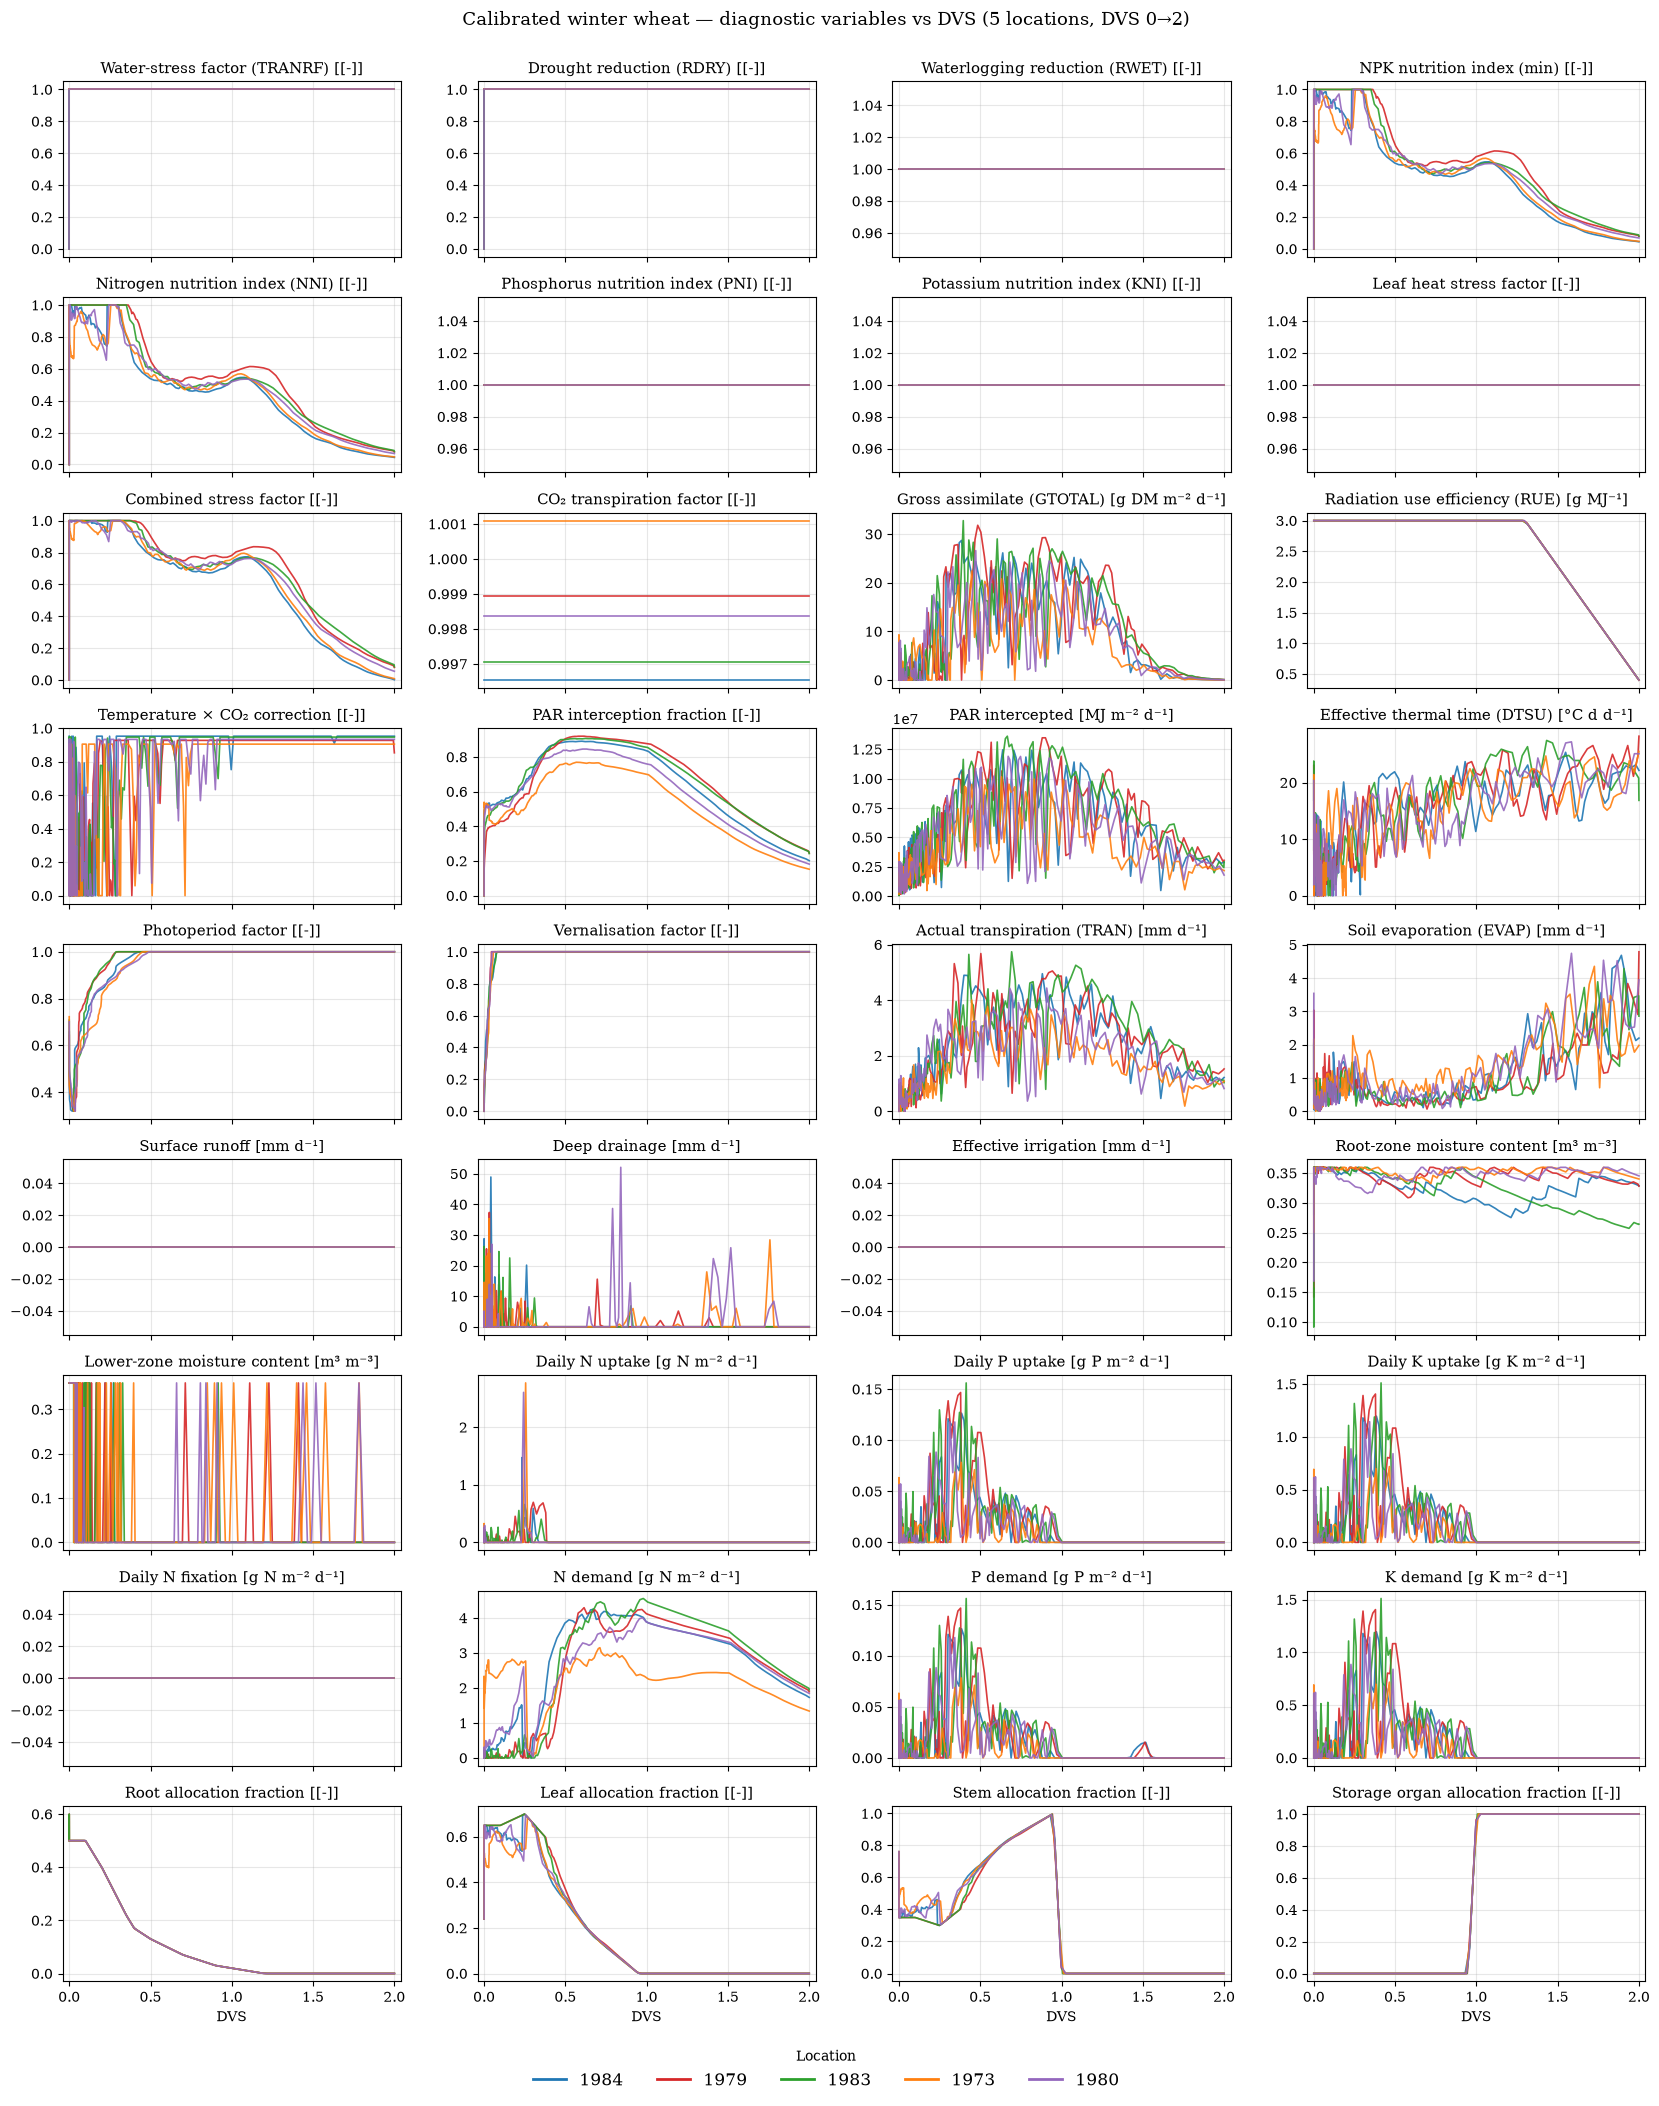

In [15]:
# Label + unit for each DiagnosticState field.
DIAG_META = {
    # Stress factors
    "tranrf": ("Water-stress factor (TRANRF)", "[-]"),
    "rdry": ("Drought reduction (RDRY)", "[-]"),
    "rwet": ("Waterlogging reduction (RWET)", "[-]"),
    "nstress": ("NPK nutrition index (min)", "[-]"),
    "nni": ("Nitrogen nutrition index (NNI)", "[-]"),
    "pni": ("Phosphorus nutrition index (PNI)", "[-]"),
    "kni": ("Potassium nutrition index (KNI)", "[-]"),
    "leaf_heat_factor": ("Leaf heat stress factor", "[-]"),
    "combined_stress": ("Combined stress factor", "[-]"),
    "co2_factor": ("CO₂ transpiration factor", "[-]"),
    # Photosynthesis / growth drivers
    "gtotal": ("Gross assimilate (GTOTAL)", "g DM m⁻² d⁻¹"),
    "rue": ("Radiation use efficiency (RUE)", "g MJ⁻¹"),
    "rtmco": ("Temperature × CO₂ correction", "[-]"),
    # Light / canopy
    "frac_intercepted": ("PAR interception fraction", "[-]"),
    "parint": ("PAR intercepted", "MJ m⁻² d⁻¹"),
    # Phenology drivers
    "dtsu": ("Effective thermal time (DTSU)", "°C d d⁻¹"),
    "photofac": ("Photoperiod factor", "[-]"),
    "vernfac": ("Vernalisation factor", "[-]"),
    # Water fluxes
    "tran": ("Actual transpiration (TRAN)", "mm d⁻¹"),
    "evap": ("Soil evaporation (EVAP)", "mm d⁻¹"),
    "runoff": ("Surface runoff", "mm d⁻¹"),
    "drain": ("Deep drainage", "mm d⁻¹"),
    "rirr": ("Effective irrigation", "mm d⁻¹"),
    "smact": ("Root-zone moisture content", "m³ m⁻³"),
    "smactl": ("Lower-zone moisture content", "m³ m⁻³"),
    # Nutrient fluxes
    "nuptr": ("Daily N uptake", "g N m⁻² d⁻¹"),
    "puptr": ("Daily P uptake", "g P m⁻² d⁻¹"),
    "kuptr": ("Daily K uptake", "g K m⁻² d⁻¹"),
    "nfixtr": ("Daily N fixation", "g N m⁻² d⁻¹"),
    "n_demand": ("N demand", "g N m⁻² d⁻¹"),
    "p_demand": ("P demand", "g P m⁻² d⁻¹"),
    "k_demand": ("K demand", "g K m⁻² d⁻¹"),
    # Partitioning fractions
    "fr": ("Root allocation fraction", "[-]"),
    "fl": ("Leaf allocation fraction", "[-]"),
    "fs": ("Stem allocation fraction", "[-]"),
    "fo": ("Storage organ allocation fraction", "[-]"),
}

# Stack the per-day DiagnosticState snapshots into a [B, T, C] array.
diag_field_names = crop_output.diagnostics[0].field_names
diag_traj = torch.stack([s.stack() for s in crop_output.diagnostics], dim=1).cpu().numpy()  # [B, T, C]

plot_trajectories(
    diag_traj,
    dvs_traj[:, :-1],
    sown_traj[:, :-1],
    diag_field_names,
    DIAG_META,
    title="Calibrated winter wheat — diagnostic variables vs DVS (5 locations, DVS 0→2)\n",
)

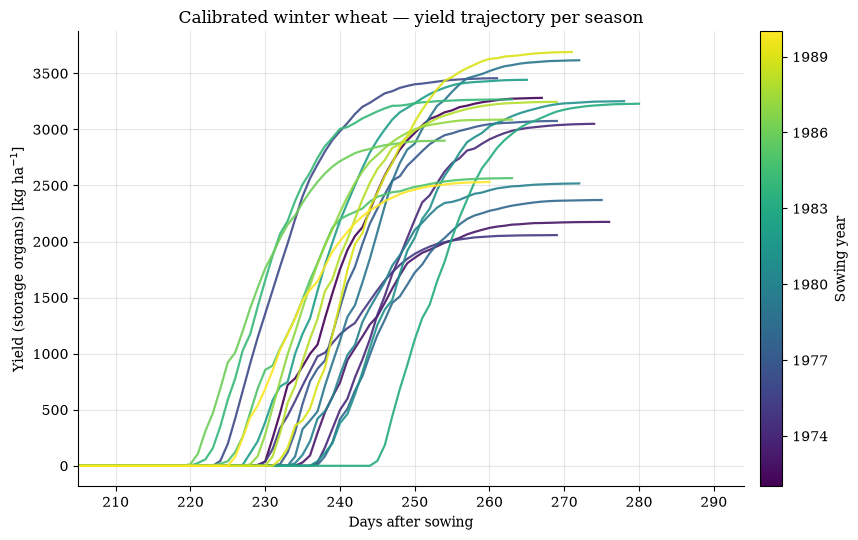

In [16]:
# Calibrated yield trajectory of every season, one line per sowing year.
# Sowing year is an ordered variable, so the lines are shaded along a single
# sequential ramp (with a colorbar) instead of 19 categorical colours.
WSO_IDX = field_names.index("wso")

norm = plt.matplotlib.colors.Normalize(vmin=min(sow_years), vmax=max(sow_years))
cmap = plt.get_cmap("viridis")

fig, ax = plt.subplots(figsize=(9, 5.5))
grain_fill_start = []
for b, sow_year in enumerate(sow_years):
    mask = mask_until_dvs2(sown_traj[b] > 0, dvs_traj[b])
    yield_kg_ha = state_traj[b, mask, WSO_IDX] * G_M2_TO_KG_HA
    grain_fill_start.append(int(np.argmax(yield_kg_ha > 1.0)))
    ax.plot(np.arange(len(yield_kg_ha)), yield_kg_ha,
            color=cmap(norm(sow_year)), lw=1.6, alpha=0.9)

# Nothing happens before grain filling, so start the axis just ahead of it.
ax.set_xlim(max(0, min(grain_fill_start) - 15), None)

ax.set_xlabel("Days after sowing")
ax.set_ylabel("Yield (storage organs) [kg ha$^{-1}$]")
ax.set_title("Calibrated winter wheat — yield trajectory per season")
ax.grid(alpha=0.3)
ax.margins(x=0.01)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, pad=0.02)
cbar.set_label("Sowing year")
cbar.set_ticks([int(y) for y in sow_years if y % 3 == 0])

fig.tight_layout()
plt.show()

## Simpest

### 5. FraNchEstYN inputs (septoria + fungicide)

torchcrop simulates crop growth only, with no pest, disease or fungicide
effects. `simpest.models.franchestyn` layers a septoria SEIR epidemic and a
fungicide-efficacy model on top of an external **attainable** crop-growth
trajectory (light interception, biomass, yield, thermal time), then reports
the **actual** (disease-limited) trajectory. The cells below convert the
calibrated torchcrop run into the three DataFrames `run_franchestyn` expects
(`weather_df`, `management_df`, `crop_model_df`).

Reference severity observations for this site come from
`notebooks/data/reference_fra/FRA_REFERENCE_Indiana.csv` (1973–1991). Three
things about them matter for the comparison:

- **They describe the upper four leaves.** Shaner and Buechley (1995) rated
  the cultivar Monon on a 0–9.5 scale and converted it to the mean percent
  area with symptoms on the flag leaf and the three leaves below it (their
  Table 2). FraNchEstYN's severity is for the whole canopy and has no leaf
  layers, so the two are not the same quantity. This notebook therefore
  switches on simpest's upper-leaf pool (`upper_leaf_pool=True`, not part of
  the C# model): a second tissue pool that opens between 36 % and 52 % of the
  crop cycle, when the upper four leaves of Monon emerge (leaf dates of 1990
  in the paper, p. 937), and is infected by the same rule as the canopy. The
  observations are compared with its severity (`UpperLeafSeverity`).
  Compared with canopy severity instead, the simulation levelled off at
  40–75 % in the severe seasons, where 88–98 % was observed: the model takes
  senesced leaf area out of the susceptible tissue, so canopy infection stops
  about two weeks after anthesis, while the assessments of the upper leaves
  continued for about three and a half weeks.
- **The pathogen changes.** Up to 1985 the leaf blotch was caused by
  *Septoria tritici*; from 1986 *Stagonospora nodorum* predominated on the
  upper leaves (paper, p. 930). The paper found no significant difference in
  its epidemic parameters between the two periods (Table 6), and one septoria
  parameter set is used here for all seasons.
- **The `FINT` column is a placeholder.** It holds 1 at heading and 0.25 at
  harvest in every year. It is not an observation of light interception.

**Weather for the disease model.** Septoria infection is driven by leaf
wetness and humidity, so the weather fed to FraNchEstYN matters more than it
does for torchcrop. `FRANCH_WEATHER_MODE` picks one of three options:

| mode | what the disease model sees |
|---|---|
| `"daily"` | daily Tmax/Tmin/rain/radiation only. RH is estimated from temperature alone, and a day's rain is spread evenly over 24 h, so any day with ≥ 4.8 mm of rain counts as 24 wet hours |
| `"daily_rh"` | as `"daily"`, plus the daily RH extremes (`RHmax`/`RHmin` columns of the same files) |
| `"hourly"` | measured hourly temperature, RH, rain and radiation (ERA5, from `tools/fetch_torchcrop_dataset.py --hourly`) |

This notebook uses `"hourly"`: the disease model gets measured hourly
temperature, RH and rain from the ERA5 file
`weather_hourly/west_lafayette.csv.gz` (fetched with
`tools/fetch_torchcrop_dataset.py --hourly`, the same fetch the daily files
were aggregated from). With daily input a day's rain is spread over 24 h,
which produces many artificial fully-wet days and makes the seasons look
alike to the infection model. torchcrop still runs on the daily files
(`weather/<sowing year>.csv`), so the two models see the same weather at
different time steps.

In [17]:
import simpest.models.franchestyn as franchestyn

FRANCH_CROP_TYPE      = "wheat"
FRANCH_DISEASE_TYPE   = "septoria"
FRANCH_FUNGICIDE_TYPE = "protectant"   # no sprays scheduled below -> runs as a no-op
FRANCH_SITE           = "west_lafayette_indiana"
FRANCH_VARIETY        = "Generic"
FRANCH_DISEASE        = "thisDisease"
FRANCH_START_YEAR     = 1972
FRANCH_END_YEAR       = 1991   # last season's (1990 sowing) disease dynamics run into mid-1991
FRANCH_USE_GDD        = True   # required whenever the crop-model series comes from an
                                # internal (Python) crop model rather than calendar-day
                                # interpolation -- see UNITS_INVESTIGATION notes.
# Weather fed to the disease model -- see the table above.
FRANCH_WEATHER_MODE   = "hourly"   # "daily", "daily_rh" or "hourly"
FRANCH_LATITUDE       = 40.4698
REFERENCE_PATH = Path("../data/reference_fra/FRA_REFERENCE_Indiana.csv")

In [18]:
from simpest.models import fr_inputs

ref_df = pd.read_csv(REFERENCE_PATH)
# Weather: concatenate the season CSVs and drop duplicate dates. The season
# windows overlap by design, and overlapping days carry identical values
# since every season file was sliced from the same source.
weather_raw = pd.concat(
    [
        pd.read_csv(dataset.weather_dir / f"{loc}.csv", parse_dates=["Date"], dayfirst=True)
        for loc in dataset.locations
    ], ignore_index=True,
    ).drop_duplicates(subset="Date").sort_values("Date").reset_index(drop=True)

# FraNchEstYN reads the same daily files as torchcrop: Tmax, Tmin, rain and
# radiation, plus the RHmax/RHmin columns torchcrop ignores. Only the "hourly"
# mode needs the hourly ERA5 records (the same fetch the daily files come from).
weather_hourly = (pd.read_csv(DATA_DIR / "weather_hourly" / "west_lafayette.csv.gz")
                  if FRANCH_WEATHER_MODE == "hourly" else None)

weather_df = fr_inputs.build_weather_df(weather_raw, site=FRANCH_SITE, mode=FRANCH_WEATHER_MODE, weather_hourly=weather_hourly)

# Management: site.csv already has one row per sowing year (IDPL = sowingDOY).
management_df = fr_inputs.build_management_df(dataset.site_data, site=FRANCH_SITE, crop=FRANCH_CROP_TYPE, variety=FRANCH_VARIETY)

print(f"weather_df ({FRANCH_WEATHER_MODE}): {len(weather_df)} rows, "f"{weather_raw['Date'].min().date()} .. {weather_raw['Date'].max().date()}")

weather_df (hourly): 175320 rows, 1972-01-01 .. 1991-07-24


In [19]:
# Pull a named field out of the stacked trajectories -> [B, T] numpy, end-of-day aligned.
def sf(field):
    return state_traj[:, 1:, field_names.index(field)]

def df_(field):
    return diag_traj[:, :, diag_field_names.index(field)]

# torchcrop biomass is g m-2; FraNchEstYN's CropModelData.agb/.yield_ are kg ha-1
# (simpest/models/fr_data.py), hence G_M2_TO_KG_HA.
# state_traj/diag_traj hold the calibrated run (section 4). Each season runs from its sowing day to the first day DVS reaches 2 (maturity);
# build_crop_model_df concatenates the seasons into one multi-year series.
crop_model_df = fr_inputs.build_crop_model_df(
    agb=(sf("wlv") + sf("wlvd") + sf("wst") + sf("wstd") + sf("wso")) * G_M2_TO_KG_HA,
    yield_=sf("wso") * G_M2_TO_KG_HA,
    fint=df_("frac_intercepted"),
    gdd=sf("tsum"),   # thermal time since emergence, torchcrop's analogue of SIMPLACE TSUM
    dvs=dvs_traj[:, 1:],
    sow_years=[int(y) for y in dataset.locations],
    sowing_doys=dataset.site_data.loc[dataset.locations, "IDPL"].astype(int).tolist(),
)
print(crop_model_df.tail())

      year  doy          agb        yield      fint          gdd  season
5115  1991  165  9578.882812  2521.964111  0.254159  2260.599609    1990
5116  1991  166  9582.832031  2525.914551  0.241102  2288.349609    1990
5117  1991  167  9584.988281  2528.069092  0.228176  2310.849609    1990
5118  1991  168  9586.795898  2529.877197  0.217339  2331.949707    1990
5119  1991  169  9588.373047  2531.454102  0.207382  2355.399658    1990


In [20]:
fr_cfg = franchestyn.FranchestynConfig(
    crop_type=FRANCH_CROP_TYPE,
    disease_type=FRANCH_DISEASE_TYPE,
    fungicide_type=FRANCH_FUNGICIDE_TYPE,
    site=FRANCH_SITE,
    variety=FRANCH_VARIETY,
    disease=FRANCH_DISEASE,
    is_calibration=True,
    calibration_variable="disease",
    use_gdd=FRANCH_USE_GDD,
    use_prev_day_alignment=True,
    weather_time_step="hourly" if FRANCH_WEATHER_MODE == "hourly" else "daily",
    latitude=FRANCH_LATITUDE,
    # The observations are for the upper four leaves, so the model tracks a
    # second tissue pool for them and calibration compares the observations
    # with that pool's severity. The pool opens between 36 % and 52 % of the
    # crop cycle (the package defaults: leaf emergence dates of cv. Monon in
    # 1990, Shaner and Buechley 1995, p. 937).
    upper_leaf_pool=True,
)

# Simulated column compared with the observed severity.
SEVERITY_COL = "UpperLeafSeverity"

# Optimizer for every calibration below (the severity calibration and the hold-out).
fr_cfg.optimizer = "optuna"  # "nelder-mead" or "optuna"; used by every stage below

# Fan independent model evaluations (Nelder-Mead restarts / Morris trajectory
# points / Optuna trials) out across worker processes instead of running them
# one at a time -- respected by whichever optimizer is chosen above.
fr_cfg.n_jobs = 5

# Damage-coefficient params excluded from calibration (cannot be identified from severity data alone).
damage_disable = {"RUEreducerDamage", "LightStealerDamage", "SenescenceAcceleratorDamage", "AssimilateSappersDamage",}
fr_cfg.disease_parameters = franchestyn.deactivate_calibration(fr_cfg.disease_parameters, damage_disable)

# Bound overrides (notebook only -- fr_disease_parameters.json keeps the canonical
# FraNchEstYN bounds). None is applied. Calibration pushes PathogenSpread (daily
# secondary-infection rate) to its canonical maximum of 0.3. Raising that maximum
# to 0.6 lowered the RMSE by only 0.3 (17.0 -> 16.7; five calibrated parameters,
# hourly weather, best of three seeds, canopy severity as the target), and
# there is no published value to justify a higher rate, so the canonical bound
# is kept.
BOUND_OVERRIDES = {}

franchestyn.apply_bound_overrides(fr_cfg.disease_parameters, BOUND_OVERRIDES)

# The non-damage disease parameters, grouped by mechanism. The sensitivity screen
# covers all of them and its plot colours them by group.
GROUPS = [
    ("A: onset & cycle timing", {"HydroThermalTimeOnset", "CyclePercentageOnset", "LatencyDuration", "SporulationDuration",}),
    ("B: environmental infection-trigger", {"WetnessDurationOptimum", "WetnessDurationMinimum", "DryCriticalInterruption","RelativeHumidityCritical", "RelativeHumidityNotLimiting", "Rain50Detachment",}),
    ("C: temperature response", {"Tmin", "Topt", "Tmax"}),
    ("D: inoculum & spread magnitude", {"OuterInoculumMax", "OuterInoculumShapeParameter", "PathogenSpread",}),
]

In [21]:
from simpest.models import fr_diagnostics
from simpest.models.fr_session import FranchestynSession

# One session holds the inputs and builds the FranchestynRunner once, so the
# weather is parsed a single time for every screen, calibration and forward
# run below. Every run applies fr_cfg's current parameter specs.
session = FranchestynSession(
    fr_cfg, FRANCH_START_YEAR, FRANCH_END_YEAR, weather_df=weather_df,
    management_df=management_df, crop_model_df=crop_model_df, ref_df=ref_df,
)
seasons = list(dataset.locations)

### 6. Parameter sensitivity screen (Morris)

`run_morris_sensitivity` uses the *same* parameter selection as calibration
(flagged for `calibration`, `disease` scope, damage parameters excluded) and the
same RMSE objective. Cost is about `n_trajectories * (k + 1)` model runs.

- **mu_star** - mean absolute effect on the severity RMSE. Higher = more
  influential.
- **sigma** - spread of the effects. High relative to mu_star = non-linear or
  interacting with other parameters.
- **mu_star_conf** - bootstrap confidence interval on mu_star.

The screen is used to see which processes the severity error responds to. It
does not select the calibrated set (section 7 explains why). With hourly
weather the onset threshold, the optimum wetness duration and the optimum
temperature lead, while `PathogenSpread`, `Rain50Detachment` and
`SporulationDuration` have little effect when all parameters vary
together. For a splash-dispersed disease that is a sign that the simulated
epidemic is driven by primary inoculum and infection conditions more than by
secondary spread up the canopy, which is the process Shaner and Buechley
(1995, p. 937) hold responsible for the differences between years.

In [22]:
from simpest.models import fr_sensitivity

# Screen every non-damage disease parameter: flag exactly those for calibration.
sa_params = set().union(*(names for _, names in GROUPS))
franchestyn.deactivate_calibration(fr_cfg.disease_parameters, set(fr_cfg.disease_parameters) - sa_params - damage_disable,)
for p in sa_params:
    fr_cfg.disease_parameters[p]["calibration"] = True

fr_cfg.is_calibration = True  # screen the calibration objective, as calibration runs it

sa = fr_sensitivity.run_morris_sensitivity(
    start_year=FRANCH_START_YEAR, end_year=FRANCH_END_YEAR, config=fr_cfg,
    weather_df=weather_df, management_df=management_df,
    crop_model_df=crop_model_df, ref_df=ref_df,
    n_trajectories=20, seed=50,
    runner=session.runner,
)
sa_df = sa["table"]
sa_df

- Morris screening 16 parameters: 20 trajectories -> 340 model runs.
- Parameters:
['disease_OuterInoculumMax', 'disease_PathogenSpread', 'disease_WetnessDurationOptimum', 'disease_WetnessDurationMinimum', 'disease_DryCriticalInterruption', 'disease_Tmin', 'disease_Topt', 'disease_Tmax', 'disease_RelativeHumidityCritical', 'disease_Rain50Detachment', 'disease_RelativeHumidityNotLimiting', 'disease_HydroThermalTimeOnset', 'disease_CyclePercentageOnset', 'disease_LatencyDuration', 'disease_SporulationDuration', 'disease_OuterInoculumShapeParameter']
- Evaluating 340 trajectory points across up to 5 worker processes (per-run progress is not shown while parallel; per-run completion is reported below).


[Parallel(n_jobs=5)]: Using backend LokyBackend with 5 concurrent workers.
[Parallel(n_jobs=5)]: Done   3 tasks      | elapsed:    4.5s
[Parallel(n_jobs=5)]: Done   8 tasks      | elapsed:    7.0s
[Parallel(n_jobs=5)]: Done  15 tasks      | elapsed:   11.3s
[Parallel(n_jobs=5)]: Done  22 tasks      | elapsed:   15.6s
[Parallel(n_jobs=5)]: Done  31 tasks      | elapsed:   21.7s
[Parallel(n_jobs=5)]: Done  40 tasks      | elapsed:   27.7s
[Parallel(n_jobs=5)]: Done  51 tasks      | elapsed:   34.6s
[Parallel(n_jobs=5)]: Done  62 tasks      | elapsed:   41.5s
[Parallel(n_jobs=5)]: Done  75 tasks      | elapsed:   50.0s
[Parallel(n_jobs=5)]: Done  88 tasks      | elapsed:   58.4s
[Parallel(n_jobs=5)]: Done 103 tasks      | elapsed:  1.1min
[Parallel(n_jobs=5)]: Done 118 tasks      | elapsed:  1.3min
[Parallel(n_jobs=5)]: Done 135 tasks      | elapsed:  1.5min
[Parallel(n_jobs=5)]: Done 152 tasks      | elapsed:  1.7min
[Parallel(n_jobs=5)]: Done 171 tasks      | elapsed:  1.9min
[Parallel(

                          parameter         mu   mu_star     sigma  mu_star_conf
      disease_HydroThermalTimeOnset  13.506975 13.661175 15.083673      5.840537
     disease_WetnessDurationOptimum   8.618250 12.937800 14.653633      4.580409
                       disease_Topt   3.590625 11.966775 16.160631      5.041730
           disease_OuterInoculumMax -11.064975 11.242125 13.129349      5.061847
            disease_LatencyDuration   4.057350  7.431000  9.081015      2.720975
     disease_WetnessDurationMinimum   2.227800  5.936700  8.154276      2.694665
disease_RelativeHumidityNotLimiting   1.379250  4.338600  5.341977      1.637701
                       disease_Tmin   3.214575  4.277325  4.945232      1.903667
   disease_RelativeHumidityCritical   0.928350  3.756300  5.415908      1.663605
                       disease_Tmax  -1.095375  2.618925  3.535579      1.039143
             disease_PathogenSpread  -0.696450  1.337550  2.781854      0.991472
       disease_CyclePercenta

[Parallel(n_jobs=5)]: Done 340 out of 340 | elapsed:  3.8min finished


,parameter,mu,mu_star,sigma,mu_star_conf
0,disease_HydroThermalTimeOnset,13.506975,13.661175,15.083673,5.840537
1,disease_WetnessDurationOptimum,8.618250,12.937800,14.653633,4.580409
2,disease_Topt,3.590625,11.966775,16.160631,5.041730
3,disease_OuterInoculumMax,-11.064975,11.242125,13.129349,5.061847
4,disease_LatencyDuration,4.057350,7.431000,9.081015,2.720975
5,disease_WetnessDurationMinimum,2.227800,5.936700,8.154276,2.694665
6,disease_RelativeHumidityNotLimiting,1.379250,4.338600,5.341977,1.637701
7,disease_Tmin,3.214575,4.277325,4.945232,1.903667
8,disease_RelativeHumidityCritical,0.928350,3.756300,5.415908,1.663605
9,disease_Tmax,-1.095375,2.618925,3.535579,1.039143


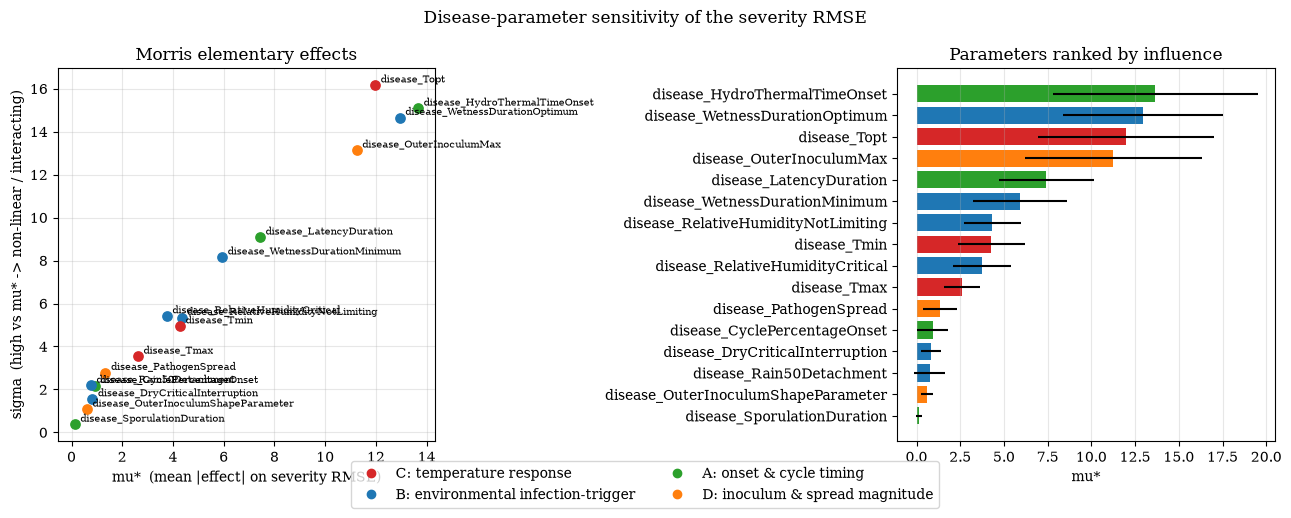

In [23]:
group_of = {p: g for g, names in GROUPS for p in names}
gname = lambda p: group_of.get(p.split('_', 1)[1], '')
gcolors = {
    "C: temperature response": "tab:red",
    "B: environmental infection-trigger": "tab:blue",
    "A: onset & cycle timing": "tab:green",
    "D: inoculum & spread magnitude": "tab:orange",
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for _, r in sa_df.iterrows():
    c = gcolors.get(gname(r["parameter"]), "0.5")
    axes[0].scatter(r["mu_star"], r["sigma"], color=c, s=45, zorder=3)
    axes[0].annotate(r["parameter"], (r["mu_star"], r["sigma"]), fontsize=7,
                     xytext=(4, 2), textcoords="offset points")
axes[0].set_xlabel("mu*  (mean |effect| on severity RMSE)")
axes[0].set_ylabel("sigma  (high vs mu* -> non-linear / interacting)")
axes[0].set_title("Morris elementary effects")
axes[0].grid(alpha=0.3)

order = sa_df.sort_values("mu_star")
bar_c = [gcolors.get(gname(p), "0.5") for p in order["parameter"]]
axes[1].barh(order["parameter"], order["mu_star"], color=bar_c,
             xerr=order["mu_star_conf"])
axes[1].set_xlabel("mu*")
axes[1].set_title("Parameters ranked by influence")
axes[1].grid(alpha=0.3, axis="x")

handles = [plt.Line2D([0], [0], marker="o", ls="", color=c, label=g)
           for g, c in gcolors.items()]
fig.legend(handles=handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Disease-parameter sensitivity of the severity RMSE", fontsize=12)
fig.tight_layout()
plt.show()

### 7. Calibrate five disease parameters

Calibrating every parameter the screen flags (eight to ten of them) does not
work here: different optimizer seeds reach the same RMSE with very different
values, several values end up on their bounds, and the extra parameters
lower the error only on the seasons they are fitted to (15.6 against 17.0
in-sample, but 23 to 24 on held-out seasons either way; these figures are
from calibrations against canopy severity, before the upper-leaf pool was
switched on). The 109 severity observations cannot pin that many parameters
down. So only five are calibrated, and everything else keeps its
canonical FraNchEstYN septoria value from
`simpest/models/fr_disease_parameters.json`. No value is changed by hand.

**Calibrated** (site- and trial-specific, no published value for this trial):

| Parameter | Why it is calibrated |
|---|---|
| `OuterInoculumMax` | Primary inoculum pressure at the site. Shaner and Buechley (1995, Discussion) report that primary inoculum is abundant every year but do not quantify it. |
| `PathogenSpread` | Secondary infection rate. The paper attributes the year-to-year differences to splash dispersal carrying infection up the canopy (Discussion, p. 937). |
| `WetnessDurationOptimum` | Among the three most influential parameters in the screen above. |
| `Topt` | Among the three most influential parameters in the screen. The canonical value of 18 °C is the lower edge of the canonical range (18–24 °C). Calibrated against canopy severity it came out at 20 to 21 °C; against the upper-leaf severity every seed returns it to about 18 °C. |
| `HydroThermalTimeOnset` | Among the three most influential parameters; sets when the epidemic starts, which the paper reports as varying strongly between years (Results, p. 930). |

**Fixed at the canonical value**: the cardinal temperatures `Tmin` and
`Tmax`, `LatencyDuration`, the two relative-humidity thresholds,
`WetnessDurationMinimum` and the parameters the screen finds inert. The cell
below prints each fixed value. Two of them can be checked against the paper:
`Tmax` = 31 °C is consistent with Septoria tritici blotch developing poorly
at 29 °C (Wainshilbaum and Lipps 1991, cited on p. 936), and
`LatencyDuration` = 19.5 d is longer than the incubation period of about
12 d at 14–15 °C observed in 1990 (p. 937), as a latent period should be.

Optuna (TPE) runs from the same start once per seed and the best seed's
values are used. Each seed takes roughly 10 minutes with `n_jobs=5`.

The cell after the calibration checks every seed's values against the
calibration bounds (`fr_diagnostics.bound_check`). A value within 5 % of a
bound usually means the optimizer wanted to go further, so that value is
compensating for something else and should not be read as an estimate. All
bounds are the canonical ones. `PathogenSpread` ends on its upper bound of
0.3; doubling that bound was tried (against canopy severity) and lowered the
RMSE by only 0.3, and no published value supports a higher rate, so the bound
is kept. `Topt` ends on its lower bound of 18 °C, which is also its canonical
value.

The three seeds reach the same RMSE (16.3 to 16.4) and agree on four of the
five values. They do not agree on `HydroThermalTimeOnset` (4.9, 5.3 and
14.5): the severity data do not identify it, and its fitted value should not
be interpreted.

In [24]:
# Calibrated set: see the table above for the reason behind each one.
CALIBRATED = ["OuterInoculumMax", "PathogenSpread", "WetnessDurationOptimum", "HydroThermalTimeOnset", "Topt"]

# sa_df names are runner keys ("disease_<Param>"); fr_cfg.disease_parameters is keyed by "<Param>".
bare = lambda p: p.split("_", 1)[1]
fixed = [bare(p) for p in sa_df["parameter"] if bare(p) not in CALIBRATED]
franchestyn.deactivate_calibration(fr_cfg.disease_parameters, set(fixed))
for p in CALIBRATED:
    fr_cfg.disease_parameters[p]["calibration"] = True
print("calibrated:", CALIBRATED)

# Fixed parameters keep the value FranchestynConfig loaded from
# simpest/models/fr_disease_parameters.json (canonical FraNchEstYN septoria
# set); nothing is overwritten here.
mu_star = sa_df.assign(parameter=sa_df["parameter"].map(bare)).set_index("parameter")["mu_star"]
fixed_table = pd.DataFrame({
    "value": {p: fr_cfg.disease_parameters[p]["value"] for p in fixed},
    "unit": {p: fr_cfg.disease_parameters[p].get("unit", "") for p in fixed},
    "mu_star": mu_star.loc[fixed].round(2),
    "source": "canonical FraNchEstYN (fr_disease_parameters.json)",
})
print("fixed:")
print(fixed_table.to_string())

# Same start for every seed; the best seed's values are written into fr_cfg.
# With fr_cfg.n_jobs > 1 Optuna evaluates trials in fixed batches, so each seed
# is reproducible.
CALIB_SEEDS = [1, 2, 3]
CALIB_TRIALS = 1200
calib = session.calibrate_seeds(CALIB_SEEDS, n_trials=CALIB_TRIALS)
best_run, start_params = calib.best, calib.start_params["disease"]
calib.table().round(3)

calibrated: ['OuterInoculumMax', 'PathogenSpread', 'WetnessDurationOptimum', 'HydroThermalTimeOnset', 'Topt']
fixed:
                             value              unit  mu_star                                              source
LatencyDuration               19.5              days     7.43  canonical FraNchEstYN (fr_disease_parameters.json)
WetnessDurationMinimum        10.0             hours     5.94  canonical FraNchEstYN (fr_disease_parameters.json)
RelativeHumidityNotLimiting   90.0          unitless     4.34  canonical FraNchEstYN (fr_disease_parameters.json)
Tmin                           7.5                °C     4.28  canonical FraNchEstYN (fr_disease_parameters.json)
RelativeHumidityCritical      60.0          unitless     3.76  canonical FraNchEstYN (fr_disease_parameters.json)
Tmax                          31.0                °C     2.62  canonical FraNchEstYN (fr_disease_parameters.json)
CyclePercentageOnset          25.0  hydrodegree days     0.92  canonical FraNchEstYN 

/home/rahaman/miniforge3/envs/simpest/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Trial 1200/1200 CURR RMSE=16.6110 BEST RMSE=16.3550
Best RMSE: 16.3550
{'disease_OuterInoculumMax': 0.15175023745591573, 'disease_PathogenSpread': 0.2985445820808318, 'disease_WetnessDurationOptimum': 13.830731077236745, 'disease_Topt': 18.007136082037142, 'disease_HydroThermalTimeOnset': 4.900902935297312}
seed 1: RMSE=16.355
- Calibrating 5 using Optuna (TPE), n_trials=1200.
- Parameters:
['disease_OuterInoculumMax', 'disease_PathogenSpread', 'disease_WetnessDurationOptimum', 'disease_Topt', 'disease_HydroThermalTimeOnset']
- Evaluating trials in batches of 5 across 5 worker processes.
Trial 1200/1200 CURR RMSE=16.6660 BEST RMSE=16.3540
Best RMSE: 16.3540
{'disease_OuterInoculumMax': 0.1495460984750067, 'disease_PathogenSpread': 0.2962218227944588, 'disease_WetnessDurationOptimum': 13.858444405851287, 'disease_Topt': 18.03999076541576, 'disease_HydroThermalTimeOnset': 5.333538501913235}
seed 2: RMSE=16.354
- Calibrating 5 using Optuna (TPE), n_trials=1200.
- Parameters:
['disease_Out

,1,2,3
RMSE,16.355,16.354,16.336
OuterInoculumMax,0.152,0.150,0.152
PathogenSpread,0.299,0.296,0.296
WetnessDurationOptimum,13.831,13.858,13.789
Topt,18.007,18.040,18.149
HydroThermalTimeOnset,4.901,5.334,14.483


In [25]:
# Calibrated values within 5 % of a calibration bound, for every seed, and the
# full table for the best seed (position: 0 = lower bound, 1 = upper bound).
bounds = {r["seed"]: fr_diagnostics.bound_check(r["best_params"], calib.start_params) for r in calib.runs}
for seed, table in bounds.items():
    print(f"seed {seed} at a bound:", table.loc[table["at_bound"] != "", "at_bound"].to_dict())
bounds[best_run["seed"]].round(3)

seed 1 at a bound: {'disease_PathogenSpread': 'upper', 'disease_Topt': 'lower'}
seed 2 at a bound: {'disease_PathogenSpread': 'upper', 'disease_Topt': 'lower'}
seed 3 at a bound: {'disease_PathogenSpread': 'upper', 'disease_Topt': 'lower'}


,value,min,max,position,at_bound
parameter,,,,,
disease_OuterInoculumMax,0.152,0.010,0.35,0.419,
disease_PathogenSpread,0.296,0.001,0.30,0.986,upper
disease_WetnessDurationOptimum,13.789,10.000,48.00,0.100,
disease_Topt,18.149,18.000,24.00,0.025,lower
disease_HydroThermalTimeOnset,14.483,0.500,20.00,0.717,


### 8. Simulated severity and yield loss

A forward run with the calibrated disease parameters gives, per season, the
severity and the disease-limited (actual) yield next to the attainable yield
from the calibrated torchcrop run. The damage coefficients that turn severity
into yield loss are not calibrated: they keep their canonical FraNchEstYN
values (`LightStealerDamage` = 1, `RUEreducerDamage` = 1,
`fr_disease_parameters.json`).

The severity figure shows two simulated curves. The solid line is the
upper-leaf pool, which the observations are compared with. The dashed line is
the whole-canopy severity, which is what damages the crop: the pool does not
enter the yield calculation. The calibrated parameters drive both, though,
and the values fitted to the upper leaves give a more severe canopy epidemic
than the values fitted to canopy severity did. The mean simulated yield loss
is 72 % here, against 60 % with that earlier calibration.

The attainable yield is a county-level yield (section 3), so the absolute
actual yields are not predictions for the trial plots. The loss in percent
is the more useful number.

In [26]:
# Forward run with the best seed's parameters.
result = session.run_forward()
summary = result["outputs"]["summary"]

# FraNchEstYN stores disease severity as a 0-1 fraction internally;
# build_season_summary expects that and multiplies by 100 for AUDPC, so
# convert to percent only after the summary is built.
simulation_df = fr_diagnostics.simulation_frame(result, severity_percent=False)
season_summary = franchestyn.build_season_summary(simulation_df, site=fr_cfg.site, variety=fr_cfg.variety)
for col in fr_diagnostics.SEVERITY_COLUMNS:
    simulation_df[col] = simulation_df[col] * 100.0
season_summary["DiseaseSeverity"] = season_summary["DiseaseSeverity"] * 100.0

print(f"FraNchEstYN completed (best seed: {best_run['seed']})")
print("RMSE (upper-leaf severity vs reference):", summary.get("rmse"))
print(f"{len(season_summary)} growing seasons summarised")
season_summary

FraNchEstYN completed (best seed: 3)
RMSE (upper-leaf severity vs reference): 16.336
19 growing seasons summarised


,GrowingSeason,Site,Variety,AUDPC,DiseaseSeverity,YieldAttainable,YieldActual,YieldLossRaw,YieldLossPerc,AGBattainable,AGBactual,AveTx,AveTn,AveRHx,AveRHn,TotalPrec,TotalRad,TotalLW
0,1972,west_lafayette_indiana,Generic,3620.212398,83.838549,3281.3910,292.701852,2988.689148,91.079946,10373.9400,5634.244877,11.215299,2.895522,87.839552,57.205224,811.0,3291.878,1611.0
1,1973,west_lafayette_indiana,Generic,3486.342625,68.687797,2175.2385,339.753750,1835.484750,84.380851,8367.9720,5009.420609,12.291697,3.093863,87.519856,57.162455,952.8,3522.663,1593.0
2,1974,west_lafayette_indiana,Generic,2422.158988,66.115509,3049.7250,891.400308,2158.324692,70.771125,10691.5320,7193.217058,11.795636,3.059636,87.974545,54.836364,680.0,3701.865,1492.0
3,1975,west_lafayette_indiana,Generic,2551.317040,56.208232,2057.4192,593.167416,1464.251784,71.169346,8737.8070,6124.669526,13.139259,2.817407,85.296296,51.000000,617.8,3829.207,1134.0
4,1976,west_lafayette_indiana,Generic,1965.931133,67.464606,3456.1780,1623.463904,1832.714096,53.027191,10872.2810,8934.566983,10.096565,0.433588,81.419847,48.893130,553.7,3684.978,816.0
5,1977,west_lafayette_indiana,Generic,2697.354958,75.167816,3075.2395,658.007851,2417.231649,78.603037,10515.2000,7086.210267,9.456296,0.335556,87.362963,59.362963,670.0,3731.382,1414.0
6,1978,west_lafayette_indiana,Generic,3083.087567,69.476098,2370.3990,319.690439,2050.708561,86.513223,9965.3540,6218.873963,10.634783,1.272101,86.710145,56.083333,743.5,3699.899,1467.0
7,1979,west_lafayette_indiana,Generic,2625.357572,80.583191,3616.4004,993.540901,2622.859499,72.526800,11455.8880,8474.661081,11.262271,2.158242,85.739927,53.937729,761.9,3577.604,1379.0
8,1980,west_lafayette_indiana,Generic,3155.557788,78.101948,2518.1323,328.243917,2189.888383,86.964787,10040.8960,6728.621254,11.487546,2.183516,84.238095,51.435897,802.1,3667.066,1076.0
9,1981,west_lafayette_indiana,Generic,2304.175761,64.838005,3251.7358,1314.095651,1937.640149,59.587871,10768.8280,7993.915212,10.649104,0.988889,87.318996,56.172043,836.7,3827.249,1376.0


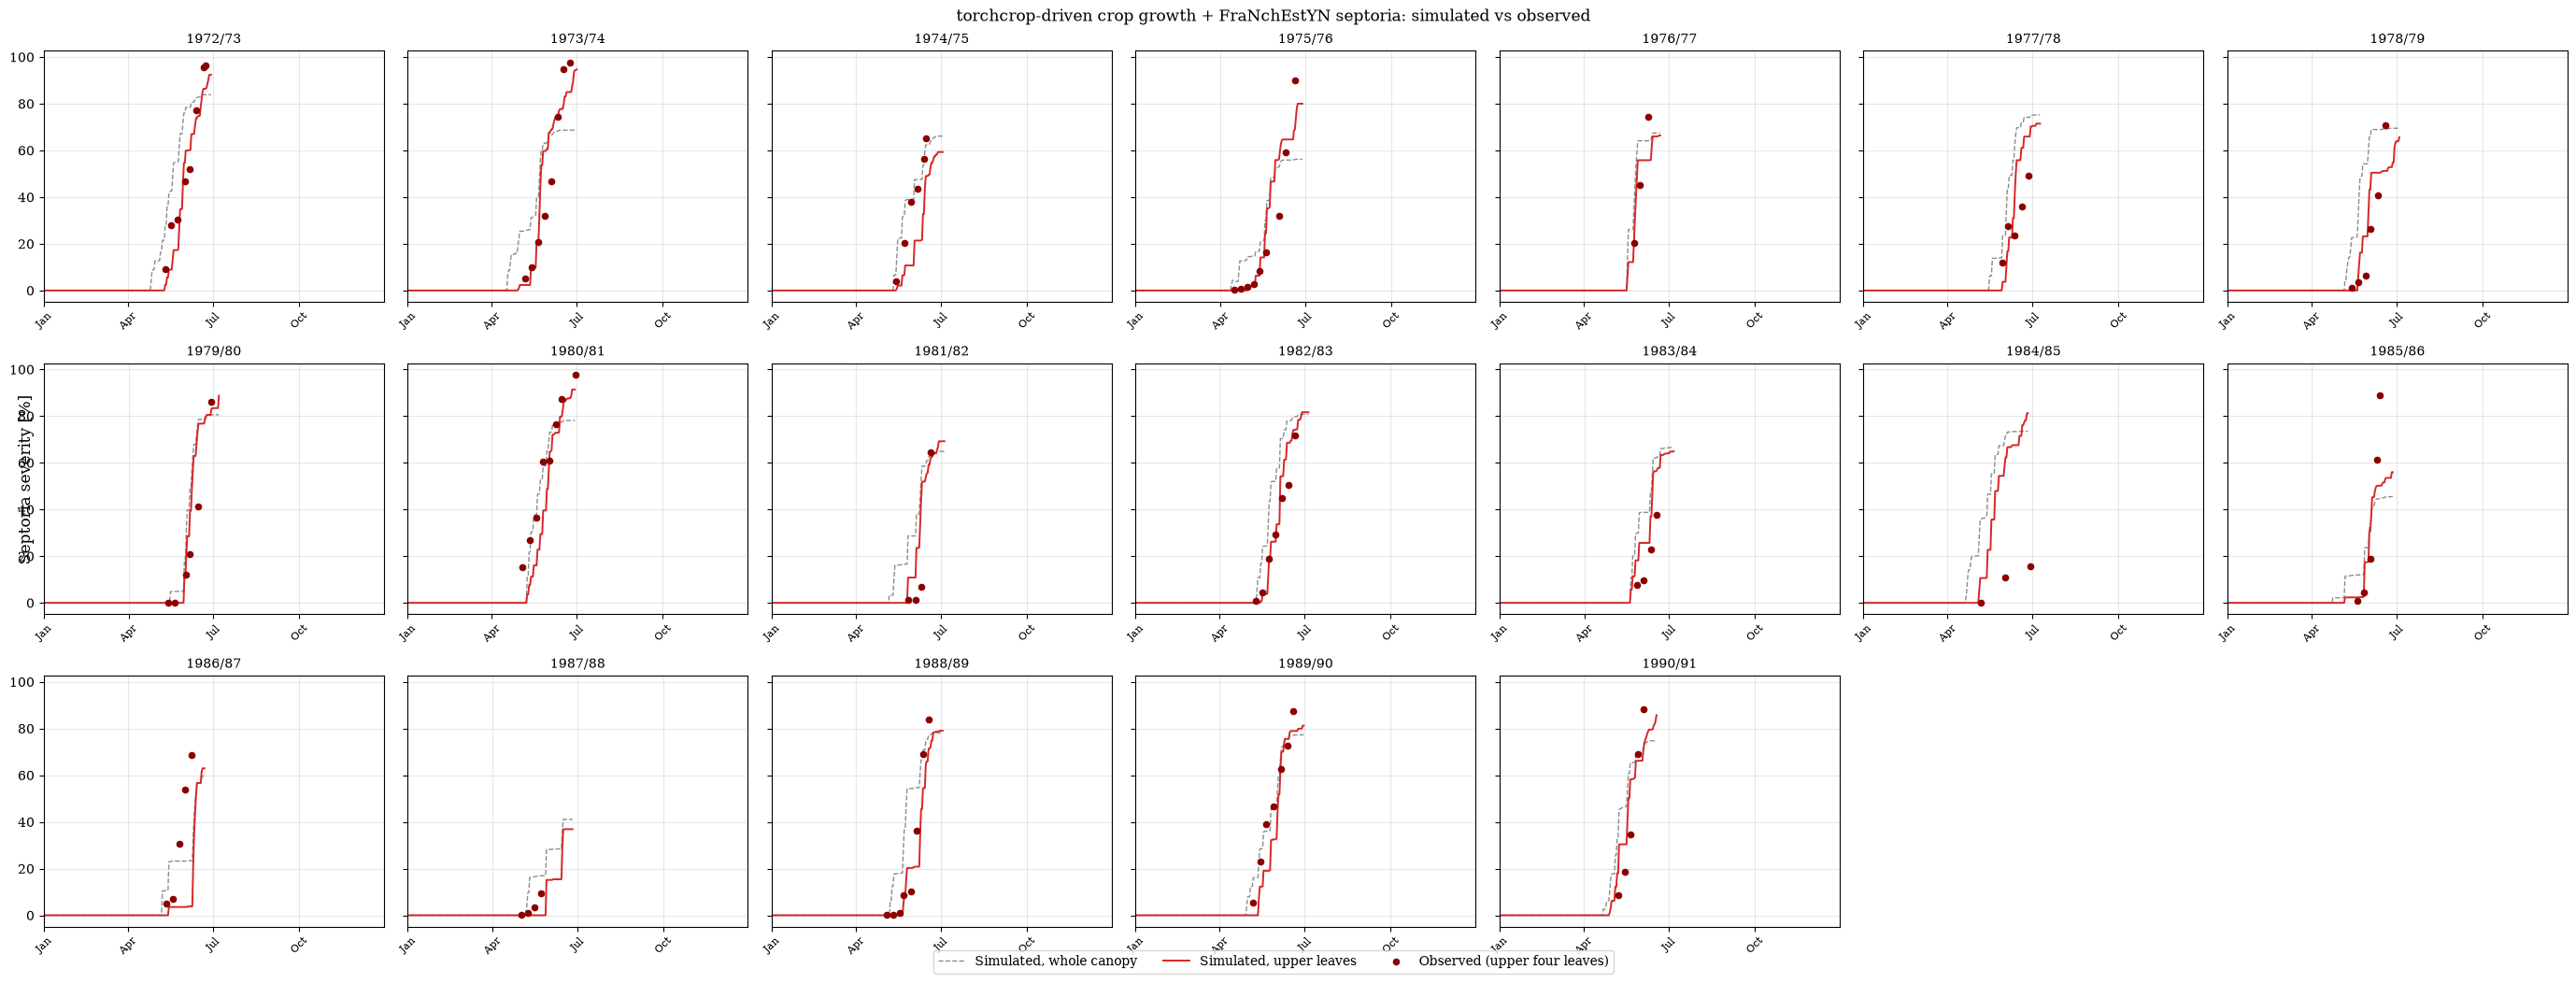

In [27]:
n_seasons = len(dataset.locations)
n_cols = 7
n_rows = int(np.ceil(n_seasons / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(28, 3.5 * n_rows), sharey=True)
axes_flat = axes.ravel()
ref_dis = ref_df[ref_df[FRANCH_DISEASE].notna()]

for i, sow_year in enumerate(dataset.locations):
    ax = axes_flat[i]
    harvest_yr = sow_year + 1
    sub = simulation_df[simulation_df["GrowingSeason"] == sow_year]
    ax.plot(sub["Date"], sub["DiseaseSeverity"], color="0.55", lw=1.0, ls="--", label="Simulated, whole canopy")
    ax.plot(sub["Date"], sub[SEVERITY_COL], color="tab:red", lw=1.4, label="Simulated, upper leaves")

    ref_yr = ref_dis[ref_dis["year"] == harvest_yr]
    if not ref_yr.empty:
        ref_dates = pd.Timestamp(year=harvest_yr, month=1, day=1) + pd.to_timedelta(ref_yr["DOY"] - 1, unit="D")
        ax.scatter(ref_dates, ref_yr[FRANCH_DISEASE], color="darkred", s=20, zorder=5, label="Observed (upper four leaves)")

    ax.set_title(f"{sow_year}/{str(harvest_yr)[2:]}", fontsize=10)
    ax.set_xlim(pd.Timestamp(f"{harvest_yr}-01-01"), pd.Timestamp(f"{harvest_yr}-12-31"))
    ax.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
    ax.tick_params(axis="x", labelsize=8, rotation=45)
    ax.grid(alpha=0.3)

# Hide any unused panels (n_seasons may not fill the grid exactly).
for ax in axes_flat[n_seasons:]:
    ax.axis("off")

handles, labels = axes_flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01))
fig.supylabel("Septoria severity [%]")
fig.suptitle("torchcrop-driven crop growth + FraNchEstYN septoria: simulated vs observed", fontsize=12)
fig.tight_layout()
plt.show()

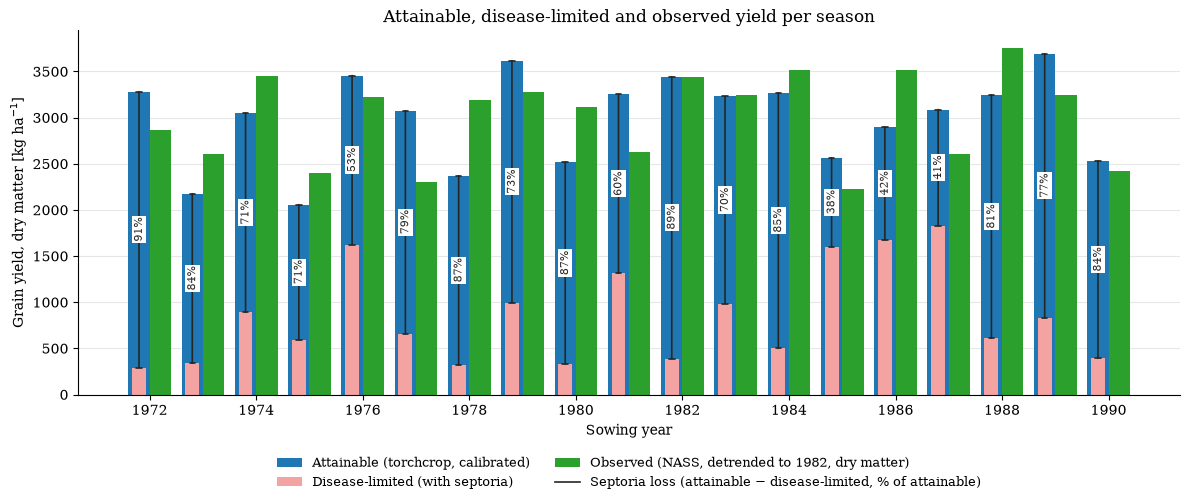

In [28]:
# Attainable (calibrated torchcrop) vs observed (detrended NASS, dry matter) yield
# per season, side by side. The disease-limited yield is drawn as a light red
# bar inside the attainable bar (opaque, so it does not blend with the blue).
# The septoria loss is the gap between the two: a line from the top of the red
# bar to the top of the blue bar, labelled with the loss in percent of the
# attainable yield. Seasons are independent, so bars rather than lines
# connecting the years.
from matplotlib.lines import Line2D

x = season_summary["GrowingSeason"].to_numpy()
observed = cmp_df.set_index("sow_year")["observed_detrended"].reindex(x).to_numpy()

fig, ax = plt.subplots(figsize=(12, 5.2))
ax.bar(x - 0.2, season_summary["YieldAttainable"], width=0.4, color="#1f77b4", label="Attainable (torchcrop, calibrated)")
ax.bar(x - 0.2, season_summary["YieldActual"], width=0.26, color="#f4a3a3",
       label="Disease-limited (with septoria)")
ax.bar(x + 0.2, observed, width=0.4, color="#2ca02c",
       label=f"Observed (NASS, detrended to {ref_harvest_year}, dry matter)")
for xi, att, act, loss in zip(x, season_summary["YieldAttainable"], season_summary["YieldActual"],
                              season_summary["YieldLossPerc"]):
    ax.annotate("", xy=(xi - 0.2, att), xytext=(xi - 0.2, act),
                arrowprops=dict(arrowstyle="|-|,widthA=0.2,widthB=0.2", color="0.15", lw=1.2,
                                shrinkA=0, shrinkB=0))
    ax.text(xi - 0.2, (att + act) / 2, f"{loss:.0f}%", rotation=90, ha="center", va="center",
            fontsize=8, color="0.15", bbox=dict(boxstyle="square,pad=0.15", fc="white", ec="none"))

ax.set_xlabel("Sowing year")
ax.set_ylabel("Grain yield, dry matter [kg ha$^{-1}$]")
ax.set_title("Attainable, disease-limited and observed yield per season")
ax.set_xticks(x[::2])
ax.set_ylim(0, None)
ax.grid(alpha=0.3, axis="y")
ax.set_axisbelow(True)
handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([], [], color="0.15", lw=1.2))
labels.append("Septoria loss (attainable − disease-limited, % of attainable)")
ax.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False, fontsize=9)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

# season_summary[["GrowingSeason", "DiseaseSeverity", "AUDPC", "YieldAttainable", "YieldActual", "YieldLossPerc"]].round(1)

#### Check: measured yield loss in 1980 (LARS plots)

The simulated loss can only be checked against a *measured* disease loss: the
yield of fungicide-treated plots compared with untreated plots of the same
cultivar, in the same season and at the same nitrogen rate. The ratio cancels
the yield level of the plots, so it does not depend on how well the
attainable yield matches them.

Such plots exist for Monon at the Purdue Agronomy Farm in 1980
(`yield/LARS_exact_plots_wheat_yield_1979_1980.csv`, from Purdue dataset
doi:10.4231/R7736NTR, whose factor codes document the treatments). The file's
`season` is read as the harvest year, so 1980 is the season sown in 1979. In
the paper's plots 1980 was a severe year (87 % of the upper four leaves
diseased at the last assessment). The 1979 plots are not used: their
fungicide codes are undocumented.

Limits: two plots per treatment and nitrogen rate, one season, and the
treated plots were probably not disease-free, so the measured loss is a lower
bound. It may also be a different field from the one where severity was
assessed.

In [29]:
# Measured loss: untreated vs fungicide-treated Monon, per nitrogen rate, 1980 harvest.
lars = pd.read_csv(DATA_DIR / "yield" / "LARS_exact_plots_wheat_yield_1979_1980.csv")
lars_1980 = lars[(lars["season"] == 1980) & (lars["variety"] == "MONON")]
measured_loss = observed_yield.measured_disease_loss(
    lars_1980, "disease_treatment",
    treated="susceptible, fungicide-treated", untreated="susceptible, untreated",
)

# Simulated loss of the same season (sown 1979, harvested 1980).
sim_loss_1980 = season_summary.loc[season_summary["GrowingSeason"] == 1979, "YieldLossPerc"].item()
print(f"Simulated septoria yield loss, season sown 1979: {sim_loss_1980:.1f} %")
measured_loss.round(1)

Simulated septoria yield loss, season sown 1979: 72.5 %


,n_rate_kg_ha,treated_mean,untreated_mean,n_treated,n_untreated,loss_pct
0,0.0,3943.2,3759.9,2,2,4.6
1,60.0,4353.1,4290.2,2,2,1.4
2,120.0,5294.2,4522.9,2,2,14.6


## 9. Error diagnostics: simulated vs observed

At every severity observation date, match the simulated value on that same
calendar date and take the residual `simulated - observed`. The parity plot
shows overall bias and spread against the 1:1 line; the residual-over-time
plot shows whether errors cluster in a particular part of the season (colour
marks over- and under-prediction).

The `FINT` values in the reference file are placeholders (1 at heading, 0.25
at harvest in every year), so the printed `fint` error only shows how far the
simulated canopy is from that assumed shape and is not plotted.

The same-date severity RMSE printed here is a little higher than the
calibration objective, because the objective compares each observation with
the simulated value of the day before (`use_prev_day_alignment`, kept for
parity with the C# model).

In [30]:
severity_err = fr_diagnostics.match_ref_to_sim(simulation_df, ref_df, seasons, FRANCH_DISEASE, SEVERITY_COL)
fint_err = fr_diagnostics.match_ref_to_sim(simulation_df, ref_df, seasons, "FINT", "LightInterception")

sev_stats, fint_stats = fr_diagnostics.error_stats(severity_err), fr_diagnostics.error_stats(fint_err)
print(f"severity: n={sev_stats['n']}  RMSE={sev_stats['RMSE']:.2f}  MAE={sev_stats['MAE']:.2f}")
print(f"fint:     n={fint_stats['n']}  RMSE={fint_stats['RMSE']:.3f}  MAE={fint_stats['MAE']:.3f}")

severity: n=109  RMSE=16.55  MAE=11.92
fint:     n=20  RMSE=0.175  MAE=0.167


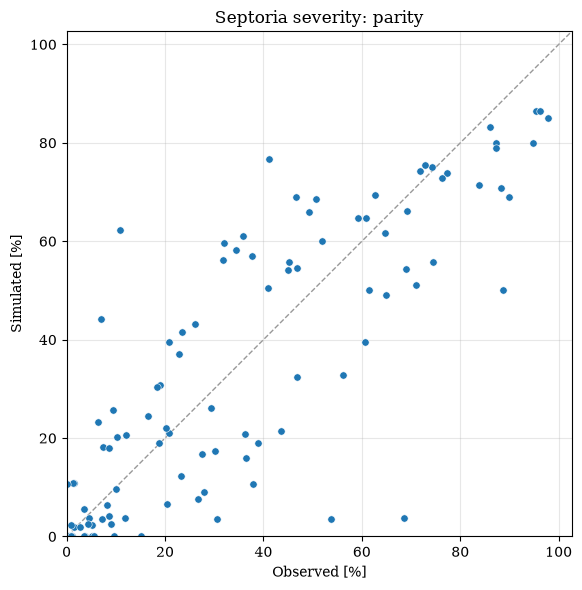

In [31]:
err_df = severity_err
lo, hi = 0, max(err_df["observed"].max(), err_df["simulated"].max()) * 1.05

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([lo, hi], [lo, hi], color="0.6", lw=1, ls="--", zorder=1)
ax.scatter(err_df["observed"], err_df["simulated"], s=28, color="tab:blue", edgecolor="white", linewidth=0.4, zorder=2)
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_aspect("equal")
ax.set_xlabel("Observed [%]")
ax.set_ylabel("Simulated [%]")
ax.set_title("Septoria severity: parity")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

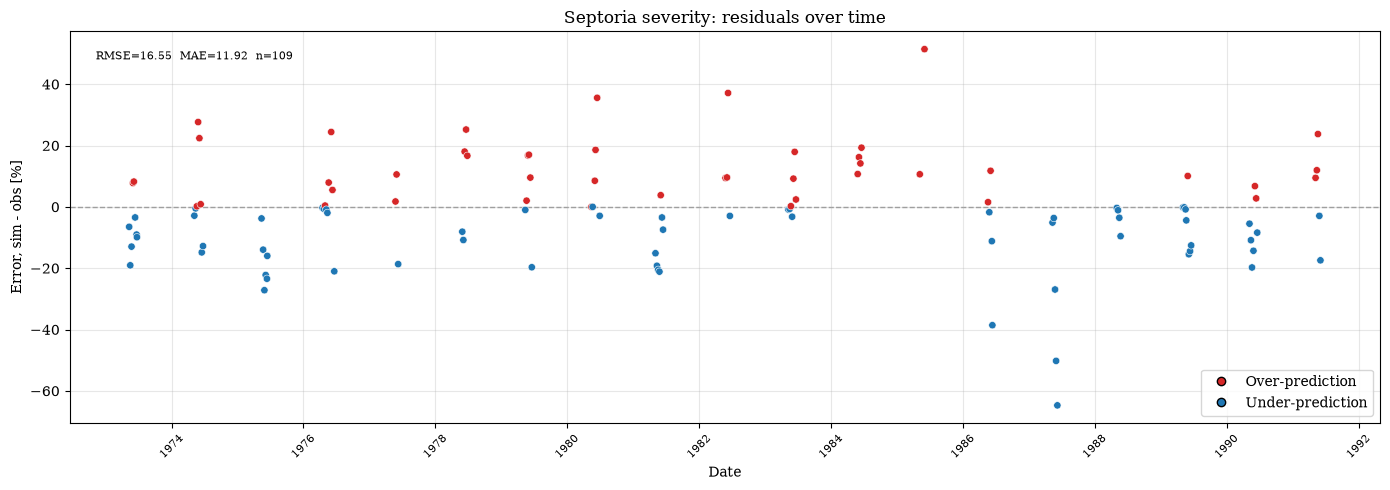

In [32]:
err_colors = np.where(err_df["error"] >= 0, "tab:red", "tab:blue")

fig, ax = plt.subplots(figsize=(14, 5))
ax.axhline(0, color="0.6", lw=1, ls="--", zorder=1)
ax.scatter(err_df["date"], err_df["error"], s=28, color=err_colors, edgecolor="white", linewidth=0.4, zorder=2)
ax.set_xlabel("Date")
ax.set_ylabel("Error, sim - obs [%]")
ax.set_title("Septoria severity: residuals over time")
ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.grid(alpha=0.3)
ax.text(0.02, 0.95, f"RMSE={sev_stats['RMSE']:.2f}  MAE={sev_stats['MAE']:.2f}  n={sev_stats['n']}",
        transform=ax.transAxes, fontsize=8, va="top")
ax.legend(handles=[
    Line2D([0], [0], marker="o", color="none", markerfacecolor="tab:red", markersize=6, label="Over-prediction"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="tab:blue", markersize=6, label="Under-prediction"),
], loc="lower right")
fig.tight_layout()
plt.show()

#### Per-season diagnostics

One row per season: fit quality (same-date RMSE and bias), simulated and
observed peak severity, when the simulated season ends compared with the last
observation, and April–June wet hours. The calibration objective only scores
observations that fall inside a simulated season, so `n_obs_after_season`
counts observations the optimizer never sees. Fully-wet days (24 wet hours)
are rare with hourly weather (0 to 2 per April–June here); with daily weather,
where a day's rain is spread evenly over 24 hours, the same seasons showed 7
to 32.

`peak_sim` is the peak of the upper-leaf severity. The severe seasons are
now reached (1972/73, 1973/74 and 1980/81 peak above 90 %), but the simulated
peaks still span a narrower range than the observed ones: the model
over-predicts the mildest epidemics (1984/85 most of all, where observed
severity never exceeded 16 %, and 1983/84 and 1987/88), under-predicts
1985/86, and in 1986/87 the simulated rise comes about two weeks late.

In [33]:
season_diag = fr_diagnostics.season_diagnostics(simulation_df, ref_df, severity_err, seasons, FRANCH_DISEASE, sim_col=SEVERITY_COL)
season_diag.round(1)

,rmse,bias,peak_sim,peak_obs,sim_end,last_obs,n_obs,n_obs_after_season,wet_hours_AMJ,fully_wet_days_AMJ
season,,,,,,,,,,
1972/73,10.6,-5.6,92.4,96.3,1973-06-29,1973-06-23,8,0,490.0,0
1973/74,14.4,2.5,94.7,97.8,1974-07-01,1974-06-24,8,0,550.0,1
1974/75,19.3,-17.8,59.3,65.0,1975-07-03,1975-06-15,6,0,413.0,0
1975/76,11.2,1.5,80.0,90.0,1976-06-28,1976-06-20,9,0,321.0,0
1976/77,12.4,-2.1,66.4,74.4,1977-06-22,1977-06-09,3,0,286.0,2
1977/78,16.9,8.2,71.5,49.2,1978-07-09,1978-06-27,5,0,442.0,0
1978/79,13.3,4.1,65.6,70.9,1979-07-04,1979-06-19,6,0,451.0,0
1979/80,16.8,10.0,88.7,86.1,1980-07-07,1980-06-29,6,0,515.0,1
1980/81,14.9,-11.9,91.4,97.8,1981-06-29,1981-06-30,8,1,522.0,2


#### Season AUDPC: simulated vs observed

Point-wise RMSE is sensitive to a few days of timing error. The area under the
disease progress curve (AUDPC) summarises each season's epidemic intensity in
one number, and it is closer to what drives yield loss. Observed and
simulated AUDPC are both integrated over each season's matched observation
dates with the trapezoid rule (`fr_diagnostics.season_audpc`), in % × days.
Observations after simulated maturity are not matched, so those seasons'
windows are shorter than the field assessments.

Because both AUDPCs grow with the length of the window, and the windows range
from about two to eight weeks, part of their correlation comes from window
length alone. The mean severity over the window (AUDPC divided by its days)
removes that and is the fairer test of season-to-season intensity.

Shaner and Buechley (1995, Tables 5 and 6) report AUDPC for every season from
the first to the last assessment. Their values, transcribed in
`disease/disease.csv` (`AUDPC_Y_recommended`, × 100),
are shown as a cross-check of the reference severities: the two agree
closely in most seasons. The CSV notes where the paper's tables are
inconsistent; 1975 and 1976 have no reliable paper value.


AUDPC, n = 19: Pearson r = 0.82, rank r = 0.81
mean severity over the window: Pearson r = 0.57, rank r = 0.59
observed 67-2227, simulated 0-2430 % x days


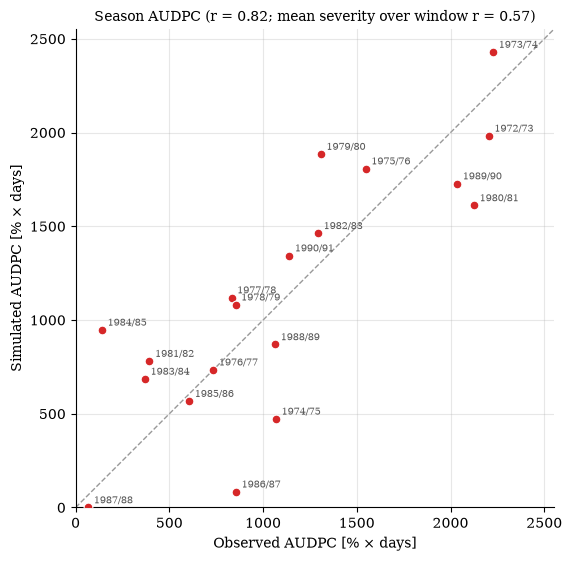

,n,first,last,observed,simulated,paper,days
season,,,,,,,
1972,8,1973-05-11,1973-06-23,2204.0,1982.0,2259.0,43
1973,8,1974-05-07,1974-06-24,2227.0,2430.0,2256.0,48
1974,6,1975-05-14,1975-06-15,1069.0,473.0,NaN,32
1975,9,1976-04-16,1976-06-20,1548.0,1808.0,NaN,65
1976,3,1977-05-25,1977-06-09,735.0,735.0,698.0,15
1977,5,1978-05-30,1978-06-27,832.0,1120.0,787.0,28
1978,6,1979-05-14,1979-06-19,853.0,1082.0,819.0,36
1979,6,1980-05-14,1980-06-29,1308.0,1886.0,1329.0,46
1980,7,1981-05-04,1981-06-15,2126.0,1611.0,2954.0,42


In [34]:
audpc = fr_diagnostics.season_audpc(severity_err)

# Paper AUDPC, proportion x days -> % x days, keyed by harvest (crop) year.
paper = pd.read_csv(DATA_DIR / "disease" / "disease.csv").set_index("crop_year")
audpc["paper"] = (paper["AUDPC_Y_recommended"] * 100).reindex(audpc.index + 1).to_numpy()

# Mean severity over the window removes the effect of window length on AUDPC.
audpc["days"] = (audpc["last"] - audpc["first"]).dt.days
mean_obs, mean_sim = audpc["observed"] / audpc["days"], audpc["simulated"] / audpc["days"]

r = np.corrcoef(audpc["observed"], audpc["simulated"])[0, 1]
r_rank = audpc["observed"].rank().corr(audpc["simulated"].rank())
r_mean = np.corrcoef(mean_obs, mean_sim)[0, 1]
print(f"AUDPC, n = {len(audpc)}: Pearson r = {r:.2f}, rank r = {r_rank:.2f}")
print(f"mean severity over the window: Pearson r = {r_mean:.2f}, "
      f"rank r = {mean_obs.rank().corr(mean_sim.rank()):.2f}")
print(f"observed {audpc['observed'].min():.0f}-{audpc['observed'].max():.0f}, "
      f"simulated {audpc['simulated'].min():.0f}-{audpc['simulated'].max():.0f} % x days")

fig, ax = plt.subplots(figsize=(5.8, 5.8))
lim = 1.05 * audpc[["observed", "simulated"]].to_numpy().max()
ax.plot([0, lim], [0, lim], color="0.6", lw=1, ls="--", zorder=1)
ax.scatter(audpc["observed"], audpc["simulated"], s=40, color="tab:red", edgecolor="white", linewidth=0.8, zorder=3)
for season, row in audpc.iterrows():
    ax.annotate(f"{season}/{str(season + 1)[2:]}", (row["observed"], row["simulated"]), xytext=(4, 3),
                textcoords="offset points", fontsize=7, color="0.35")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_aspect("equal")
ax.set_xlabel("Observed AUDPC [% × days]")
ax.set_ylabel("Simulated AUDPC [% × days]")
ax.set_title(f"Season AUDPC (r = {r:.2f}; mean severity over window r = {r_mean:.2f})", fontsize=10)
ax.grid(alpha=0.3)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

audpc.round({"observed": 0, "simulated": 0, "paper": 0})

## 10. Hold-out check

Every result above is calibrated and scored on the same 19 seasons. To see
whether the poorly fitted seasons are a compromise of that joint fit or a
structural limit of the model, recalibrate on 13 seasons only (same starting
values, bounds, trial budget and seed as the best all-seasons run) and score
the 6 held-out seasons. The held-out set mixes well- and poorly-fitted
seasons. If the train-only fit scores much worse on the held-out seasons than
the all-seasons fit does, the calibrated parameters do not generalise to
seasons they were not fitted on.

With five calibrated parameters the two fits score about the same on the
held-out seasons (mean season RMSE 17.6 and 18.8), so the calibration
overfits little. The held-out seasons are fitted somewhat worse than the
training seasons (about 18 to 19 against 16). Most of that gap is one season,
1984/85, whose weak epidemic the model does not reproduce. About 19 severity
points is the number to quote as the predictive error for severity. With
canopy severity as the target it was 23 to 24.

In [35]:
HOLDOUT = [1973, 1975, 1978, 1981, 1984, 1988]  # sowing years
ref_train = ref_df[~ref_df["year"].isin([y + 1 for y in HOLDOUT])]

# Same starting values, bounds, trial budget and seed as the best all-seasons run.
ho_cfg = copy.deepcopy(fr_cfg)
ho_cfg.disease_parameters = copy.deepcopy(start_params)
ho_cfg.is_calibration, ho_cfg.n_trials, ho_cfg.seed = True, CALIB_TRIALS, best_run["seed"]

train_session = FranchestynSession(
    ho_cfg, FRANCH_START_YEAR, FRANCH_END_YEAR, weather_df=weather_df,
    management_df=management_df, crop_model_df=crop_model_df, ref_df=ref_train,
)
ho_best = train_session.run()
franchestyn.apply_best_params(ho_cfg, ho_best["outputs"]["summary"]["best_params"])

# Score every season with the train-only parameters, on the all-seasons runner.
ho_cfg.is_calibration = False
ho_sim = fr_diagnostics.simulation_frame(
    franchestyn.run_franchestyn(config=ho_cfg, runner=session.runner, **session.inputs))

holdout_table = pd.DataFrame({
    "all_seasons_fit": fr_diagnostics.season_rmse(severity_err),
    "train_only_fit": fr_diagnostics.season_rmse(
        fr_diagnostics.match_ref_to_sim(ho_sim, ref_df, seasons, FRANCH_DISEASE, SEVERITY_COL)),
})
holdout_table["held_out"] = holdout_table.index.isin(HOLDOUT)
print(holdout_table.groupby("held_out").mean().round(2))
holdout_table.round(1)

- Calibrating 5 using Optuna (TPE), n_trials=1200.
- Parameters:
['disease_OuterInoculumMax', 'disease_PathogenSpread', 'disease_WetnessDurationOptimum', 'disease_Topt', 'disease_HydroThermalTimeOnset']
- Evaluating trials in batches of 5 across 5 worker processes.
Trial 1200/1200 CURR RMSE=17.1320 BEST RMSE=16.8680
Best RMSE: 16.8680
{'disease_OuterInoculumMax': 0.15449014911354358, 'disease_PathogenSpread': 0.29963227799207853, 'disease_WetnessDurationOptimum': 10.05633795369235, 'disease_Topt': 18.113502575280574, 'disease_HydroThermalTimeOnset': 16.246937778681357}
          all_seasons_fit  train_only_fit
held_out                                 
False               15.59           15.83
True                17.56           18.80


,all_seasons_fit,train_only_fit,held_out
season,,,
1972,10.6,10.4,False
1973,14.4,16.0,True
1974,19.3,17.1,False
1975,11.2,12.2,True
1976,12.4,12.4,False
1977,16.9,19.7,False
1978,13.3,13.9,True
1979,16.8,17.7,False
1980,14.9,14.0,False


### 11. Summary and limits

**Crop growth**

- Phenology: `TSUM1` = 869 and `TSUM2` = 760 °C d reproduce the reference
  anthesis and maturity dates within about 3 days. Anthesis is the observed
  heading date shifted by a few days; maturity is derived, not observed.
- Yield: a fertiliser-N recovery fraction of 0.36 brings the simulated yield
  to the level of the detrended county yields (RMSE about 460 kg ha⁻¹) and
  keeps a correlation of 0.51 with their year-to-year variation.

**Disease**

- Severity of the upper four leaves: RMSE 16 to 17 severity points over 109
  observations, and about 19 on seasons left out of the calibration.
- Seasons: simulated and observed peak severity correlate at about 0.6. The
  simulated peaks span roughly 37–95 %, the observed ones 10–98 %.
- Yield loss: 38 to 91 % by season, 72 % on average, with the canonical
  damage coefficients.

**Limits**

1. The attainable yield is a county-level farm yield, not the disease-free
   yield of the trial plots. Trial yields from the Purdue performance-trial
   bulletins would remove this limit.
2. The level of yield loss comes from the canonical damage coefficients and
   is not checked against a measured loss at this site. It also depends on
   which severity the disease parameters are fitted to: fitted to the upper
   leaves they give a mean loss of 72 %, fitted to canopy severity 60 %.
3. `HydroThermalTimeOnset` is not identified by the data, and
   `PathogenSpread` and `Topt` sit on their bounds. The model's secondary
   spread does not reproduce the weather-driven progress up the canopy that
   the paper describes.
4. The observed severity is for the upper four leaves and covers two
   pathogens; the model has one pathogen and represents the upper leaves by
   one pool that opens over a fixed part of the crop cycle.
5. The disease model is a Python port of FraNchEstYN. The upper-leaf pool is
   a simpest addition that is not in the C# model; it leaves the canopy
   equations unchanged.